In [2]:

# ============================================================
# CÉLULA 0 — ESCOLHA DOS PARÂMETROS (OBRIGATÓRIO)
# Confira/altere os valores e clique em "Confirmar parâmetros".
# RANDOM FOREST — PENSE2024
# ============================================================

import ipywidgets as widgets
from IPython.display import display, clear_output

_n_estimators = widgets.Dropdown(
    options=[
        ('100 árvores', 100),
        ('200 árvores (padrão atual)', 200),
        ('300 árvores', 300),
        ('500 árvores', 500),
        ('1000 árvores', 1000)
    ],
    value=200,
    description='N estimators:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='420px')
)

_max_depth = widgets.Dropdown(
    options=[
        ('Sem limite (None)', None),
        ('10 níveis', 10),
        ('20 níveis', 20),
        ('30 níveis', 30),
        ('50 níveis', 50)
    ],
    value=None,
    description='Max depth:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='420px')
)

_min_samples_split = widgets.Dropdown(
    options=[
        ('2 (padrão)', 2),
        ('5', 5),
        ('10', 10),
        ('20', 20)
    ],
    value=2,
    description='Min samples split:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='420px')
)

_min_samples_leaf = widgets.Dropdown(
    options=[
        ('1', 1),
        ('2 (padrão atual)', 2),
        ('5', 5),
        ('10', 10),
        ('20', 20)
    ],
    value=2,
    description='Min samples leaf:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='420px')
)

_max_features = widgets.Dropdown(
    options=[
        ('sqrt (recomendado)', 'sqrt'),
        ('log2', 'log2'),
        ('Todas as variáveis', None)
    ],
    value='sqrt',
    description='Max features:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='420px')
)

_criterion = widgets.Dropdown(
    options=[
        ('Gini', 'gini'),
        ('Entropia', 'entropy'),
        ('Log loss', 'log_loss')
    ],
    value='gini',
    description='Criterion:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='420px')
)

_class_weight = widgets.Dropdown(
    options=[
        ('Balanceado', 'balanced'),
        ('Balanceado por árvore', 'balanced_subsample'),
        ('Sem balanceamento', None)
    ],
    value='balanced',
    description='Class weight:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='420px')
)

_random_state = widgets.IntText(
    value=42,
    description='Random state:',
    style={'description_width': 'initial'}
)

_test_size = widgets.Dropdown(
    options=[
        ('10% teste / 90% treino', 0.10),
        ('20% teste / 80% treino (atual)', 0.20),
        ('25% teste / 75% treino', 0.25),
        ('30% teste / 70% treino', 0.30),
        ('40% teste / 60% treino', 0.40)
    ],
    value=0.20,
    description='Divisão treino/teste:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='420px')
)

_confirmar = widgets.Button(
    description='Confirmar parâmetros',
    button_style='success',
    icon='check'
)

_status = widgets.Output()
_PARAMETROS_CONFIRMADOS = False

_painel = widgets.VBox([
    widgets.HTML('<h3>Configuração do Random Forest — PENSE2024</h3>'),
    widgets.HTML(
        '<p>Os valores atuais já estão selecionados. '
        'Confirme-os ou escolha outros antes do treinamento.</p>'
    ),
    _n_estimators,
    _max_depth,
    _min_samples_split,
    _min_samples_leaf,
    _max_features,
    _criterion,
    _class_weight,
    _random_state,
    _test_size,
    _confirmar,
    _status
], layout=widgets.Layout(
    border='1px solid #cccccc',
    padding='12px',
    width='500px'
))


def _confirmar_parametros(_):
    global N_ESTIMATORS, MAX_DEPTH, MIN_SAMPLES_SPLIT
    global MIN_SAMPLES_LEAF, MAX_FEATURES, CRITERION
    global CLASS_WEIGHT, RANDOM_STATE, TEST_SIZE
    global N_JOBS, _PARAMETROS_CONFIRMADOS

    with _status:
        clear_output(wait=True)

        N_ESTIMATORS = int(_n_estimators.value)
        MAX_DEPTH = _max_depth.value
        MIN_SAMPLES_SPLIT = int(_min_samples_split.value)
        MIN_SAMPLES_LEAF = int(_min_samples_leaf.value)
        MAX_FEATURES = _max_features.value
        CRITERION = _criterion.value
        CLASS_WEIGHT = _class_weight.value
        RANDOM_STATE = int(_random_state.value)
        TEST_SIZE = float(_test_size.value)
        N_JOBS = -1

        _PARAMETROS_CONFIRMADOS = True

        print('Parâmetros confirmados:')
        print(f'  n_estimators={N_ESTIMATORS}')
        print(f'  max_depth={MAX_DEPTH!r}')
        print(f'  min_samples_split={MIN_SAMPLES_SPLIT}')
        print(f'  min_samples_leaf={MIN_SAMPLES_LEAF}')
        print(f'  max_features={MAX_FEATURES!r}')
        print(f'  criterion={CRITERION!r}')
        print(f'  class_weight={CLASS_WEIGHT!r}')
        print(f'  random_state={RANDOM_STATE}')
        print(f'  treino/teste={1-TEST_SIZE:.0%}/{TEST_SIZE:.0%}')
        print(f'  n_jobs={N_JOBS}')
        print()
        print('Agora execute a célula de treinamento (Célula 1).')


_confirmar.on_click(_confirmar_parametros)

display(_painel)


Hiperparâmetros recebidos da Célula 0:
  N_ESTIMATORS = 200
  MAX_DEPTH = None
  MIN_SAMPLES_SPLIT = 2
  MIN_SAMPLES_LEAF = 2
  MAX_FEATURES = sqrt
  CRITERION = gini
  CLASS_WEIGHT = balanced
  TEST_SIZE = 0.2
  RANDOM_STATE = 42


## 1. Dataset overview

Dataset shape: (118036, 39)
Number of observations: 118,036
Number of columns: 39


,Data type,Missing values,Missing (%),Unique values
CAPITAL - indica se é município da capital,category,0,0.0,2
B01001A - Qual é o seu sexo?,category,0,0.0,2
"IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS",category,0,0.0,2
B01002 - Qual é a sua cor ou raça?,category,0,0.0,6
B01006 - Você mora com sua mãe?,category,0,0.0,3
B01007 - Você mora com seu pai?,category,0,0.0,3
B01015B - Na sua casa tem computador ou notebook?,category,0,0.0,3
B01016 - Você tem acesso à internet em sua casa?,category,0,0.0,3
"B03006B - NOS ÚLTIMOS 7 DIAS, sem contar as aulas de educação física da escola, em quantos dias você praticou alguma atividade física?",category,0,0.0,3
"B03010C - Quantas horas por dia você costuma ficar sentado(a), assistindo televisão, jogando videogame, usando computador, celular, tablet ou fazendo outras atividades sentado(a)? (NÃO contar sábado, domingo, feriados ou o tempo sentado na escola)",category,0,0.0,3



Column names:
['CAPITAL - indica se é município da capital', 'B01001A - Qual é o seu sexo?', 'IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS', 'B01002 - Qual é a sua cor ou raça?', 'B01006 - Você mora com sua mãe?', 'B01007 - Você mora com seu pai?', 'B01015B - Na sua casa tem computador ou notebook?', 'B01016 - Você tem acesso à internet em sua casa?', 'B03006B - NOS ÚLTIMOS 7 DIAS, sem contar as aulas de educação física da escola, em quantos dias você praticou alguma atividade física?', 'B03010C - Quantas horas por dia você costuma ficar sentado(a), assistindo televisão, jogando videogame, usando computador, celular, tablet ou fazendo outras atividades sentado(a)? (NÃO contar sábado, domingo, feriados ou o tempo sentado na escola)', 'B05002A - Alguma vez na vida você tomou um copo ou uma dose de bebida alcoólica?', 'B07002 - NOS ÚLTIMOS 30 DIAS, com que frequência sua mãe, pai ou responsável sabia realmente o que você estava fazendo em seu tempo livre?', 'B07004 - NOS ÚLTIMOS 30 DIAS,

## 2. Target variable analysis

... (6 outputs left out)

## 4. Model evaluation

,Metric,Score
0,Accuracy,0.7706
1,Balanced accuracy,0.7521
2,Weighted precision,0.7769
3,Weighted recall,0.7706
4,Weighted F1-score,0.7730
5,Macro precision,0.7417
6,Macro recall,0.7521
7,Macro F1-score,0.7460
8,Majority-class baseline accuracy,0.6707



Classification report:
              precision    recall  f1-score   support

           1       0.84      0.81      0.83     15741
           3       0.64      0.70      0.67      7729

    accuracy                           0.77     23470
   macro avg       0.74      0.75      0.75     23470
weighted avg       0.78      0.77      0.77     23470



## 5. Confusion matrix

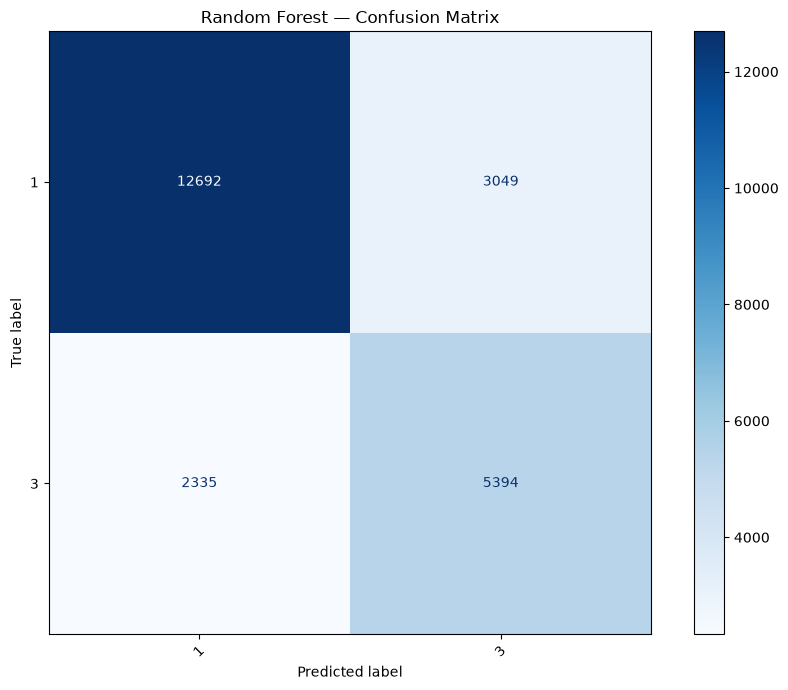

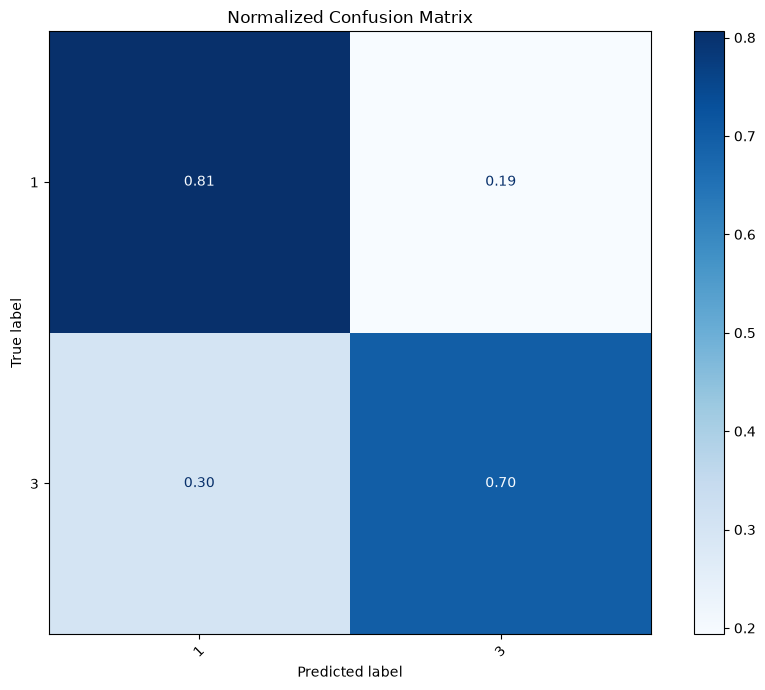

## 6. ROC-AUC

Binary ROC-AUC: 0.8305


## 7. Feature importance

Top 25 encoded categories:


,Encoded feature,Importance
87,"B12008 - NOS ÚLTIMOS 30 DIAS, com que frequênc...",0.076684
89,"B12008 - NOS ÚLTIMOS 30 DIAS, com que frequênc...",0.052798
77,"B12005 - NOS ÚLTIMOS 30 DIAS, com que frequênc...",0.047684
75,"B12005 - NOS ÚLTIMOS 30 DIAS, com que frequênc...",0.042766
79,"B12006 - NOS ÚLTIMOS 30 DIAS, com que frequênc...",0.028053
104,B09016A1 - Alguma vez na vida alguém o(a) toco...,0.020460
88,"B12008 - NOS ÚLTIMOS 30 DIAS, com que frequênc...",0.020069
103,B09016A1 - Alguma vez na vida alguém o(a) toco...,0.020059
85,"B12007 - NOS ÚLTIMOS 30 DIAS, com que frequênc...",0.019245
81,"B12006 - NOS ÚLTIMOS 30 DIAS, com que frequênc...",0.018752


Top 20 original questionnaire variables:


,Original variable,Importance
26,"B12008 - NOS ÚLTIMOS 30 DIAS, com que frequênc...",0.149695
23,"B12005 - NOS ÚLTIMOS 30 DIAS, com que frequênc...",0.101953
24,"B12006 - NOS ÚLTIMOS 30 DIAS, com que frequênc...",0.055428
31,B09016A1 - Alguma vez na vida alguém o(a) toco...,0.040788
25,"B12007 - NOS ÚLTIMOS 30 DIAS, com que frequênc...",0.038025
12,"B07004 - NOS ÚLTIMOS 30 DIAS, com que frequênc...",0.033850
1,B01001A - Qual é o seu sexo?,0.031262
3,B01002 - Qual é a sua cor ou raça?,0.030925
22,"B12004 - NOS ÚLTIMOS 30 DIAS, com que frequênc...",0.026190
35,"E01P117 - NOS ÚLTIMOS 12 MESES, a escola conto...",0.025548


/var/folders/6q/rl1jn5t52qg9qxc6f3l113480000gn/T/ipykernel_22949/1860680563.py:450: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


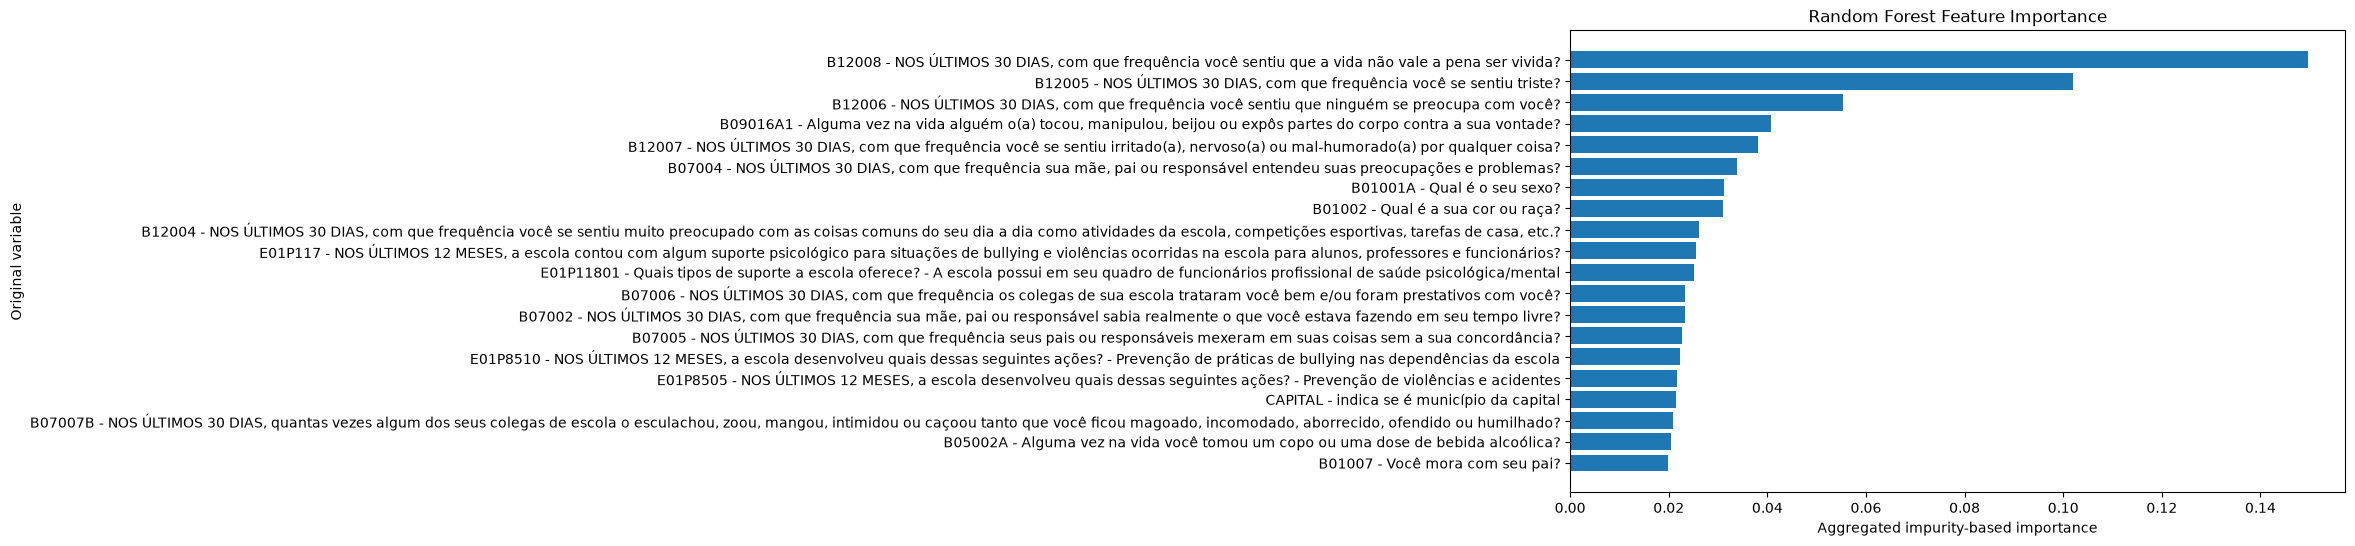

## 8. Permutation importance

Permutation importance could not be calculated: columns are missing: {'B07013 - NOS ÚLTIMOS 30 DIAS, você se sentiu ameaçado(a), ofendido(a) ou humilhado(a) nas redes sociais ou aplicativos de celular?', 'B09001 - NOS ÚLTIMOS 30 DIAS, em quantos dias você deixou de ir à escola porque não se sentia seguro NO CAMINHO de casa para a escola ou da escola para casa?', 'B01015B - Na sua casa tem computador ou notebook?', 'IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS', 'B09016A2 - Alguma vez na vida alguém ameaçou, intimidou ou obrigou a ter relações sexuais ou qualquer outro ato sexual contra a sua vontade?', 'B09002 - NOS ÚLTIMOS 30 DIAS, em quantos dias você não foi à escola porque não se sentia seguro NA ESCOLA?', 'B07011A - NOS ÚLTIMOS 30 DIAS, quantas vezes algum dos seus colegas de escola se recusou a falar com você, deixou você de lado sem razão ou fez com que outros colegas deixassem de falar com você?', 'B07012A - NOS ÚLTIMOS 30 DIAS, quantas vezes algum dos seus colegas de escola ba

## 9. Final summary

,Item,Result
0,Target variable,"B12009 - NOS ÚLTIMOS 12 MESES, alguma vez você..."
1,Training observations,"93,877"
2,Testing observations,"23,470"
3,Predictor variables,38
4,Number of classes,2
5,Random Forest trees,200
6,Accuracy,0.7706
7,Balanced accuracy,0.7521
8,Weighted F1-score,0.7730
9,Macro F1-score,0.7460



Analysis completed. No external result files were saved.


In [3]:

# ============================================================
# RANDOM FOREST CLASSIFIER — PENSE 2024
# All results are displayed directly in the Jupyter Notebook.
# No external files are saved.
# ============================================================

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Markdown

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_fscore_support,
    roc_auc_score
)
from sklearn.inspection import permutation_importance
from sklearn.dummy import DummyClassifier

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

FILE_PATH = (
    "/Users/claudiojacomassi/Documents/GitHub/"
    "Suicidio_adolescentes_Brasil/"
    "02_Tratamento_dados_database_PENSE_2024/"
    "02_Scripts_tratamento_dados_PENSE_2024/"
    "07_PENSE2024_IDADE_13_A_17_CATEGORY.feather"
)

# CHANGE THIS to the column you want to predict.
TARGET_COLUMN = "B12009 - NOS ÚLTIMOS 12 MESES, alguma vez você sentiu vontade de se machucar de propósito?"

# ------------------------------------------------------------
# VALIDAR OS PARÂMETROS DEFINIDOS NA CÉLULA 0
# ------------------------------------------------------------

if not globals().get("_PARAMETROS_CONFIRMADOS", False):
    raise RuntimeError(
        "Execute a Célula 0, selecione os hiperparâmetros "
        "e clique em 'Confirmar parâmetros' antes de continuar."
    )

print("Hiperparâmetros recebidos da Célula 0:")
print(f"  N_ESTIMATORS = {N_ESTIMATORS}")
print(f"  MAX_DEPTH = {MAX_DEPTH}")
print(f"  MIN_SAMPLES_SPLIT = {MIN_SAMPLES_SPLIT}")
print(f"  MIN_SAMPLES_LEAF = {MIN_SAMPLES_LEAF}")
print(f"  MAX_FEATURES = {MAX_FEATURES}")
print(f"  CRITERION = {CRITERION}")
print(f"  CLASS_WEIGHT = {CLASS_WEIGHT}")
print(f"  TEST_SIZE = {TEST_SIZE}")
print(f"  RANDOM_STATE = {RANDOM_STATE}")

# ------------------------------------------------------------
# 2. LOAD DATA
# ------------------------------------------------------------

df = pd.read_feather(FILE_PATH)

display(Markdown("## 1. Dataset overview"))

print(f"Dataset shape: {df.shape}")
print(f"Number of observations: {len(df):,}")
print(f"Number of columns: {df.shape[1]:,}")

display(pd.DataFrame({
    "Data type": df.dtypes.astype(str),
    "Missing values": df.isna().sum(),
    "Missing (%)": (df.isna().mean() * 100).round(2),
    "Unique values": df.nunique(dropna=True)
}).sort_values("Missing (%)", ascending=False))

print("\nColumn names:")
print(df.columns.tolist())

if TARGET_COLUMN == "REPLACE_WITH_TARGET_COLUMN":
    raise ValueError(
        "Set TARGET_COLUMN to the name of the variable "
        "you want to predict, then rerun this cell."
    )

if TARGET_COLUMN not in df.columns:
    raise ValueError(
        f"Target '{TARGET_COLUMN}' was not found. "
        "Check the column names printed above."
    )

# 
# ------------------------------------------------------------
# 3. PREPARE DATA — KEEP TARGET CLASSES 1 AND 3 ONLY
# ------------------------------------------------------------

display(Markdown("## 2. Target variable analysis"))

# Keep only observations where Target is 1 or 3.
data = df.loc[df[TARGET_COLUMN].isin([1, 3])].copy()

# Remove rows with missing target values implicitly through filtering.
X = data.drop(columns=[TARGET_COLUMN]).copy()
y = data[TARGET_COLUMN].copy()

# Ensure predictors are treated as categorical.
for col in X.columns:
    X[col] = X[col].astype(object)

# Remove constant predictors.
constant_cols = [
    col for col in X.columns
    if X[col].nunique(dropna=True) <= 1
]
X.drop(columns=constant_cols, inplace=True)

# Remove predictors containing only missing values.
all_missing_cols = [
    col for col in X.columns
    if X[col].isna().all()
]
X.drop(columns=all_missing_cols, inplace=True)

print(f"Original observations: {len(df):,}")
print(f"Observations with Target = 1 or 3: {len(data):,}")
print(f"Observations excluded: {len(df) - len(data):,}")
print(f"Predictor variables retained: {X.shape[1]}")
print(f"Constant columns removed: {len(constant_cols)}")
print(f"All-missing columns removed: {len(all_missing_cols)}")

print("\nTarget class distribution:")
display(
    y.value_counts()
     .sort_index()
     .rename_axis("Target")
     .to_frame("Count")
     .assign(
         Percentage=lambda t:
         (t["Count"] / len(y) * 100).round(2)
     )
)

# Encode the target as categorical labels if desired.
# The original values 1 and 3 are preserved.
assert set(y.unique()) == {1, 3}, (
    "The target must contain both classes 1 and 3."
)


# ------------------------------------------------------------
# 4. TRAIN / TEST SPLIT
# ------------------------------------------------------------

# Stratification preserves class proportions when feasible.
class_counts = y.value_counts()
stratify_y = (
    y if class_counts.min() >= 2
    and len(class_counts) * 2 <= len(y)
    else None
)

if stratify_y is None:
    print(
        "Warning: stratified splitting is not feasible "
        "for this target distribution."
    )

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=stratify_y
)

print(f"\nTraining observations: {len(X_train):,}")
print(f"Testing observations: {len(X_test):,}")

# ------------------------------------------------------------
# 5. PREPROCESS CATEGORICAL VARIABLES
# ------------------------------------------------------------

categorical_cols = X_train.columns.tolist()

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("cat", categorical_pipeline, categorical_cols)
])

# ------------------------------------------------------------
# 6. RANDOM FOREST MODEL
# ------------------------------------------------------------

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=N_ESTIMATORS,
        max_depth=MAX_DEPTH,
        min_samples_leaf=MIN_SAMPLES_LEAF,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=N_JOBS
    ))
])

display(Markdown("## 3. Train Random Forest"))

rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_test)

print("Random Forest training completed.")
print(f"Number of trees: {N_ESTIMATORS}")
print(f"Maximum depth: {MAX_DEPTH}")
print(f"Minimum samples per leaf: {MIN_SAMPLES_LEAF}")

# ------------------------------------------------------------
# 7. EVALUATION METRICS
# ------------------------------------------------------------

display(Markdown("## 4. Model evaluation"))

accuracy = accuracy_score(y_test, y_pred)
balanced_acc = balanced_accuracy_score(y_test, y_pred)

precision, recall, f1, _ = precision_recall_fscore_support(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

macro_precision, macro_recall, macro_f1, _ = (
    precision_recall_fscore_support(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )
)

# Majority-class baseline for comparison.
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)
baseline_accuracy = accuracy_score(y_test, baseline_pred)

metrics_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Balanced accuracy",
        "Weighted precision",
        "Weighted recall",
        "Weighted F1-score",
        "Macro precision",
        "Macro recall",
        "Macro F1-score",
        "Majority-class baseline accuracy"
    ],
    "Score": [
        accuracy,
        balanced_acc,
        precision,
        recall,
        f1,
        macro_precision,
        macro_recall,
        macro_f1,
        baseline_accuracy
    ]
})

display(
    metrics_df.style.format({"Score": "{:.4f}"})
)

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

# ------------------------------------------------------------
# 8. CONFUSION MATRIX
# ------------------------------------------------------------

display(Markdown("## 5. Confusion matrix"))

labels = rf_model.named_steps["classifier"].classes_

fig, ax = plt.subplots(figsize=(9, 7))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=labels,
    xticks_rotation=45,
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title("Random Forest — Confusion Matrix")
plt.tight_layout()
plt.show()

# Row-normalized confusion matrix: proportions per true class.
cm = confusion_matrix(y_test, y_pred, labels=labels)
row_sums = cm.sum(axis=1, keepdims=True)

cm_normalized = np.divide(
    cm,
    row_sums,
    out=np.zeros_like(cm, dtype=float),
    where=row_sums != 0
)

fig, ax = plt.subplots(figsize=(9, 7))

display_obj = ConfusionMatrixDisplay(
    confusion_matrix=cm_normalized,
    display_labels=labels
)

display_obj.plot(
    ax=ax,
    cmap="Blues",
    values_format=".2f",
    xticks_rotation=45,
    colorbar=True
)

ax.set_title("Normalized Confusion Matrix")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. ROC-AUC (WHEN APPROPRIATE)
# ------------------------------------------------------------

display(Markdown("## 6. ROC-AUC"))

try:
    classifier = rf_model.named_steps["classifier"]
    probabilities = rf_model.predict_proba(X_test)

    if len(classifier.classes_) == 2:
        # Binary classification.
        auc = roc_auc_score(
            y_test,
            probabilities[:, 1],
            labels=classifier.classes_
        )
        print(f"Binary ROC-AUC: {auc:.4f}")

    else:
        # Multiclass ROC-AUC requires all relevant classes
        # to be represented in the test set.
        auc = roc_auc_score(
            y_test,
            probabilities,
            labels=classifier.classes_,
            multi_class="ovr",
            average="weighted"
        )
        print(f"Multiclass weighted ROC-AUC: {auc:.4f}")

except ValueError as e:
    print("ROC-AUC could not be calculated:", e)

# ------------------------------------------------------------
# 10. FEATURE IMPORTANCE
# ------------------------------------------------------------

display(Markdown("## 7. Feature importance"))

# Impurity-based importance for the one-hot encoded features.
encoder = (
    rf_model.named_steps["preprocessor"]
    .named_transformers_["cat"]
    .named_steps["onehot"]
)

encoded_names = encoder.get_feature_names_out(
    categorical_cols
)

encoded_importances = (
    rf_model.named_steps["classifier"].feature_importances_
)

encoded_importance_df = pd.DataFrame({
    "Encoded feature": encoded_names,
    "Importance": encoded_importances
}).sort_values("Importance", ascending=False)

print("Top 25 encoded categories:")
display(encoded_importance_df.head(25))

# Aggregate importance back to the original questionnaire variables.
# Each one-hot encoded category contributes to its original variable.
original_importances = {}

for col in categorical_cols:
    matching = [
        i for i, name in enumerate(encoded_names)
        if name == col or name.startswith(col + "_")
    ]
    original_importances[col] = encoded_importances[matching].sum()

importance_df = pd.DataFrame({
    "Original variable": list(original_importances.keys()),
    "Importance": list(original_importances.values())
}).sort_values("Importance", ascending=False)

print("Top 20 original questionnaire variables:")
display(importance_df.head(20))

top_n = min(20, len(importance_df))
plot_df = importance_df.head(top_n).sort_values("Importance")

fig, ax = plt.subplots(figsize=(10, max(6, top_n * 0.3)))

ax.barh(
    plot_df["Original variable"],
    plot_df["Importance"]
)

ax.set_title("Random Forest Feature Importance")
ax.set_xlabel("Aggregated impurity-based importance")
ax.set_ylabel("Original variable")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 11. PERMUTATION IMPORTANCE ON ORIGINAL VARIABLES
# ------------------------------------------------------------

# This measures how much test performance declines when an
# original predictor is shuffled. It can be more interpretable
# than impurity importance, but costs additional computation.

display(Markdown("## 8. Permutation importance"))

# Limit to the top original variables from the first importance
# analysis to keep computation manageable.
PERMUTATION_TOP_N = min(20, X_train.shape[1])

selected_features = importance_df[
    "Original variable"
].head(PERMUTATION_TOP_N).tolist()

try:
    perm = permutation_importance(
        rf_model,
        X_test[selected_features],
        y_test,
        scoring="f1_weighted",
        n_repeats=3,
        random_state=RANDOM_STATE,
        n_jobs=1
    )

    permutation_df = pd.DataFrame({
        "Variable": selected_features,
        "Mean importance": perm.importances_mean,
        "Std. deviation": perm.importances_std
    }).sort_values("Mean importance", ascending=False)

    display(permutation_df)

    plot_perm = permutation_df.sort_values("Mean importance")

    fig, ax = plt.subplots(
        figsize=(10, max(6, len(plot_perm) * 0.3))
    )

    ax.barh(
        plot_perm["Variable"],
        plot_perm["Mean importance"],
        xerr=plot_perm["Std. deviation"]
    )

    ax.axvline(0, linestyle="--")
    ax.set_title("Permutation Importance — Test Set")
    ax.set_xlabel("Decrease in weighted F1 when shuffled")
    ax.set_ylabel("Original variable")

    plt.tight_layout()
    plt.show()

except Exception as e:
    print("Permutation importance could not be calculated:", e)

# ------------------------------------------------------------
# 12. FINAL SUMMARY
# ------------------------------------------------------------

display(Markdown("## 9. Final summary"))

summary_df = pd.DataFrame({
    "Item": [
        "Target variable",
        "Training observations",
        "Testing observations",
        "Predictor variables",
        "Number of classes",
        "Random Forest trees",
        "Accuracy",
        "Balanced accuracy",
        "Weighted F1-score",
        "Macro F1-score",
        "Baseline accuracy"
    ],
    "Result": [
        TARGET_COLUMN,
        f"{len(X_train):,}",
        f"{len(X_test):,}",
        X_train.shape[1],
        y.nunique(),
        N_ESTIMATORS,
        f"{accuracy:.4f}",
        f"{balanced_acc:.4f}",
        f"{f1:.4f}",
        f"{macro_f1:.4f}",
        f"{baseline_accuracy:.4f}"
    ]
})

display(summary_df)

print("\nAnalysis completed. No external result files were saved.")


## Curvas ROC — treino e teste

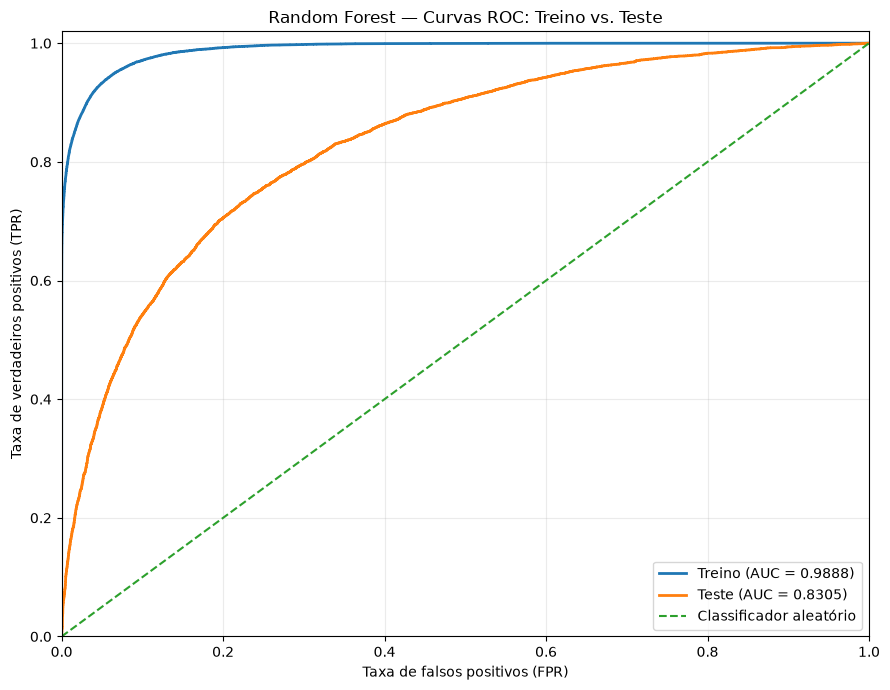

ROC-AUC treino: 0.9888
ROC-AUC teste:  0.8305
Interpretação: uma AUC de 1,0 indica separação perfeita; 0,5 indica desempenho semelhante ao acaso. A AUC de treino costuma ser mais otimista; use principalmente a AUC de teste para avaliar a generalização.


## Matrizes de confusão — treino e teste

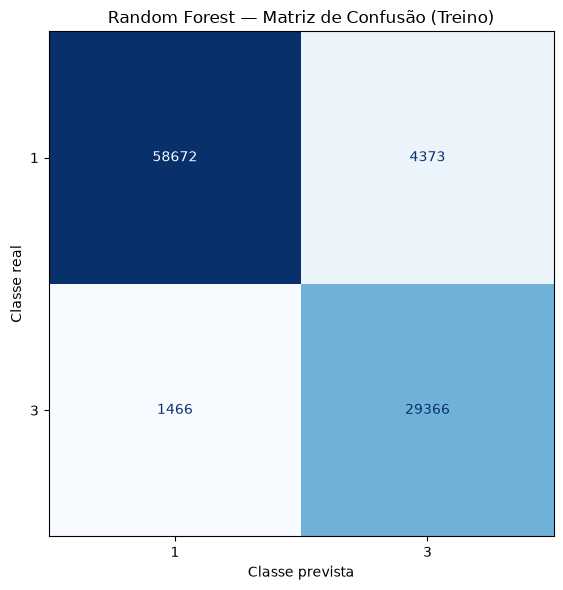

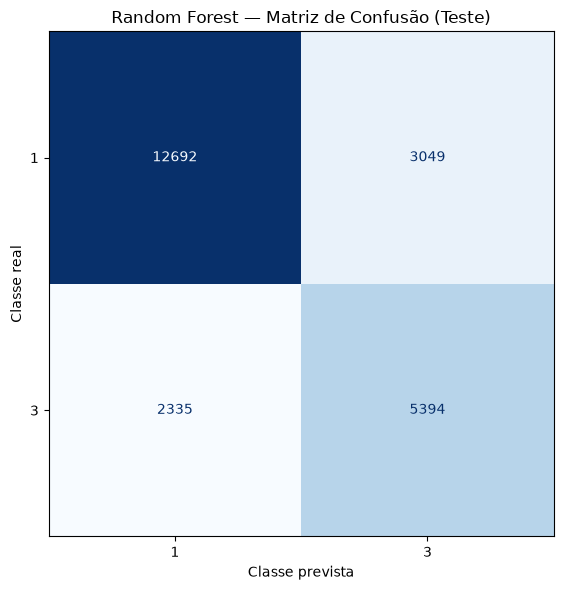

Relatório de classificação — conjunto de treino:
              precision    recall  f1-score   support

           1       0.98      0.93      0.95     63045
           3       0.87      0.95      0.91     30832

    accuracy                           0.94     93877
   macro avg       0.92      0.94      0.93     93877
weighted avg       0.94      0.94      0.94     93877

Relatório de classificação — conjunto de teste:
              precision    recall  f1-score   support

           1       0.84      0.81      0.83     15741
           3       0.64      0.70      0.67      7729

    accuracy                           0.77     23470
   macro avg       0.74      0.75      0.75     23470
weighted avg       0.78      0.77      0.77     23470



In [4]:
# ============================================================
# CÉLULA ADICIONAL — CURVAS ROC (TREINO E TESTE)
#                       + MATRIZ DE CONFUSÃO (TESTE)
# Execute após a célula principal de treinamento do Random Forest.
# Classes-alvo esperadas: 1 e 3; classe positiva para ROC: 3.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

display(Markdown("## Curvas ROC — treino e teste"))

# Obter as classes e garantir que a classe positiva 3 exista.
classificador = rf_model.named_steps["classifier"]
classes_modelo = list(classificador.classes_)

def encontrar_classe(valor):
    for classe in classes_modelo:
        if str(classe).strip() == str(valor):
            return classe
        try:
            if float(classe) == float(valor):
                return classe
        except (TypeError, ValueError):
            pass
    raise ValueError(
        f"A classe {valor} não foi encontrada. "
        f"Classes do modelo: {classes_modelo}"
    )

classe_positiva = encontrar_classe(3)

# Calcular probabilidades da classe positiva para treino e teste.
indice_positivo = classes_modelo.index(classe_positiva)
y_train_bin = (np.asarray(y_train) == classe_positiva).astype(int)
y_test_bin = (np.asarray(y_test) == classe_positiva).astype(int)

prob_train = rf_model.predict_proba(X_train)[:, indice_positivo]
prob_test = rf_model.predict_proba(X_test)[:, indice_positivo]

# Curvas ROC e AUC.
fpr_train, tpr_train, _ = roc_curve(y_train_bin, prob_train)
fpr_test, tpr_test, _ = roc_curve(y_test_bin, prob_test)

auc_train = roc_auc_score(y_train_bin, prob_train)
auc_test = roc_auc_score(y_test_bin, prob_test)

fig, ax = plt.subplots(figsize=(9, 7))
ax.plot(
    fpr_train, tpr_train,
    label=f"Treino (AUC = {auc_train:.4f})",
    linewidth=2
)
ax.plot(
    fpr_test, tpr_test,
    label=f"Teste (AUC = {auc_test:.4f})",
    linewidth=2
)
ax.plot([0, 1], [0, 1], linestyle="--", label="Classificador aleatório")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.set_xlabel("Taxa de falsos positivos (FPR)")
ax.set_ylabel("Taxa de verdadeiros positivos (TPR)")
ax.set_title("Random Forest — Curvas ROC: Treino vs. Teste")
ax.legend(loc="lower right")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(f"ROC-AUC treino: {auc_train:.4f}")
print(f"ROC-AUC teste:  {auc_test:.4f}")
print(
    "Interpretação: uma AUC de 1,0 indica separação perfeita; "
    "0,5 indica desempenho semelhante ao acaso. A AUC de treino "
    "costuma ser mais otimista; use principalmente a AUC de teste "
    "para avaliar a generalização."
)

# ------------------------------------------------------------

# MATRIZES DE CONFUSÃO — TREINO E TESTE
# ------------------------------------------------------------

display(Markdown("## Matrizes de confusão — treino e teste"))

ordem_classes = [encontrar_classe(1), encontrar_classe(3)]

# Predições para os dois conjuntos usando o mesmo modelo treinado.
y_pred_train = rf_model.predict(X_train)
y_pred_test = rf_model.predict(X_test)

cm_train = confusion_matrix(y_train, y_pred_train, labels=ordem_classes)
cm_test = confusion_matrix(y_test, y_pred_test, labels=ordem_classes)

# Matriz de confusão do treino.
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(
    confusion_matrix=cm_train,
    display_labels=ordem_classes
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)
ax.set_title("Random Forest — Matriz de Confusão (Treino)")
ax.set_xlabel("Classe prevista")
ax.set_ylabel("Classe real")
plt.tight_layout()
plt.show()

# Matriz de confusão do teste.
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(
    confusion_matrix=cm_test,
    display_labels=ordem_classes
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)
ax.set_title("Random Forest — Matriz de Confusão (Teste)")
ax.set_xlabel("Classe prevista")
ax.set_ylabel("Classe real")
plt.tight_layout()
plt.show()

print("Relatório de classificação — conjunto de treino:")
print(classification_report(
    y_train,
    y_pred_train,
    labels=ordem_classes,
    zero_division=0
))

print("Relatório de classificação — conjunto de teste:")
print(classification_report(
    y_test,
    y_pred_test,
    labels=ordem_classes,
    zero_division=0
))


In [4]:

# ============================================================
# CÉLULA FINAL — RESPOSTAS ALEATÓRIAS E PREVISÃO RANDOM FOREST
# Não cria arquivos externos
# Target original: 1 e 3 (Target 0 excluído)
# ============================================================

import pandas as pd
import numpy as np
from IPython.display import display, Markdown

# ------------------------------------------------------------
# 1. CONFIGURAÇÃO
# ------------------------------------------------------------

# Modelo Random Forest já treinado na célula anterior:
# rf_model = Pipeline([... RandomForestClassifier(...) ...])

colunas_perguntas = list(X.columns)

print(f"Número de variáveis preditoras: {len(colunas_perguntas)}")

if len(colunas_perguntas) != 38:
    print(
        f"ATENÇÃO: foram encontradas {len(colunas_perguntas)} "
        "variáveis, em vez de 38. O código utilizará "
        "as variáveis efetivamente usadas pelo modelo."
    )

# Novo sorteio a cada execução.
rng = np.random.default_rng()

# ------------------------------------------------------------
# 2. GERAR RESPOSTAS ALEATÓRIAS
# ------------------------------------------------------------

respostas = {}

for coluna in colunas_perguntas:

    # Categorias observadas no conjunto de treinamento.
    valores_validos = X_train[coluna].dropna().unique().tolist()

    if len(valores_validos) == 0:
        raise ValueError(
            f"Não existem respostas válidas para: {coluna}"
        )

    # Sorteia uma categoria observada para cada variável.
    respostas[coluna] = rng.choice(valores_validos)

# Criar uma observação com a mesma estrutura dos preditores.
novo_estudante = pd.DataFrame(
    [respostas],
    columns=colunas_perguntas
).astype(object)

# ------------------------------------------------------------
# 3. VERIFICAR AS CLASSES DO RANDOM FOREST
# ------------------------------------------------------------

# O código anterior utiliza um Pipeline chamado rf_model,
# cujo classificador final é chamado "classifier".

classificador = rf_model.named_steps["classifier"]
classes_modelo = list(classificador.classes_)

if len(classes_modelo) != 2:
    raise ValueError(
        f"Esperadas 2 classes (Target 1 e 3), mas o modelo "
        f"possui as classes: {classes_modelo}"
    )

# Localizar as classes originais 1 e 3, aceitando também
# rótulos armazenados como strings.
def localizar_classe_original(valor_original):
    for classe in classes_modelo:
        try:
            if str(classe).strip() == str(valor_original):
                return classe
            if float(classe) == float(valor_original):
                return classe
        except (ValueError, TypeError):
            continue

    raise ValueError(
        f"A classe original {valor_original} não foi encontrada "
        f"no modelo. Classes disponíveis: {classes_modelo}"
    )

classe_1 = localizar_classe_original(1)
classe_3 = localizar_classe_original(3)

# ------------------------------------------------------------
# 4. PREVER O TARGET
# ------------------------------------------------------------

probabilidades = rf_model.predict_proba(novo_estudante)[0]

prob_target_1 = float(
    probabilidades[classes_modelo.index(classe_1)]
)
prob_target_3 = float(
    probabilidades[classes_modelo.index(classe_3)]
)

classe_prevista = rf_model.predict(novo_estudante)[0]

if str(classe_prevista).strip() == str(classe_1).strip():
    rotulo_previsto = "Target 1"
elif str(classe_prevista).strip() == str(classe_3).strip():
    rotulo_previsto = "Target 3"
else:
    rotulo_previsto = f"Classe {classe_prevista}"

# ------------------------------------------------------------
# 5. MOSTRAR AS RESPOSTAS ALEATÓRIAS
# ------------------------------------------------------------

tabela_respostas = pd.DataFrame({
    "Variável": colunas_perguntas,
    "Resposta aleatória": [
        respostas[c] for c in colunas_perguntas
    ]
})

display(Markdown("## Respostas aleatórias geradas"))
display(tabela_respostas)

# ------------------------------------------------------------
# 6. MOSTRAR A PREVISÃO DO RANDOM FOREST
# ------------------------------------------------------------

resultado = pd.DataFrame({
    "Resultado": [
        "Probabilidade — Target 1",
        "Probabilidade — Target 3",
        "Classe prevista pelo Random Forest"
    ],
    "Valor": [
        f"{prob_target_1:.2%}",
        f"{prob_target_3:.2%}",
        rotulo_previsto
    ]
})

display(Markdown("## Resultado da previsão"))
display(resultado)

# ------------------------------------------------------------
# 7. RESUMO
# ------------------------------------------------------------

print("=" * 65)
print("RESUMO DA PREVISÃO — RANDOM FOREST")
print("=" * 65)
print(f"Variáveis utilizadas: {len(colunas_perguntas)}")
print(f"Classe prevista: {rotulo_previsto}")
print(f"Probabilidade Target 1: {prob_target_1:.2%}")
print(f"Probabilidade Target 3: {prob_target_3:.2%}")

print(
    "\nNota: as respostas são sorteadas independentemente "
    "entre as categorias observadas no treino. A combinação "
    "pode não representar um respondente real da PeNSE. "
    "As probabilidades são estimativas do modelo, não "
    "probabilidades clínicas individuais."
)


Número de variáveis preditoras: 38


## Respostas aleatórias geradas

,Variável,Resposta aleatória
0,CAPITAL - indica se é município da capital,0
1,B01001A - Qual é o seu sexo?,1
2,"IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS",3
3,B01002 - Qual é a sua cor ou raça?,4
4,B01006 - Você mora com sua mãe?,1
5,B01007 - Você mora com seu pai?,0
6,B01015B - Na sua casa tem computador ou notebook?,3
7,B01016 - Você tem acesso à internet em sua casa?,1
8,"B03006B - NOS ÚLTIMOS 7 DIAS, sem contar as au...",3
9,B03010C - Quantas horas por dia você costuma f...,3


## Resultado da previsão

,Resultado,Valor
0,Probabilidade — Target 1,37.88%
1,Probabilidade — Target 3,62.12%
2,Classe prevista pelo Random Forest,Target 3


RESUMO DA PREVISÃO — RANDOM FOREST
Variáveis utilizadas: 38
Classe prevista: Target 3
Probabilidade Target 1: 37.88%
Probabilidade Target 3: 62.12%

Nota: as respostas são sorteadas independentemente entre as categorias observadas no treino. A combinação pode não representar um respondente real da PeNSE. As probabilidades são estimativas do modelo, não probabilidades clínicas individuais.


DIAGNÓSTICO DO DICIONÁRIO PENSE 2024
Variáveis no Random Forest: 38
Variáveis encontradas no Excel: 38
Variáveis sem correspondência: 0
Cobertura do dicionário: 100.00%


CONFERÊNCIA DAS TRADUÇÕES

Variável: CAPITAL
Pergunta: CAPITAL - indica se é município da capital
Respostas observadas:
  0 -> Código 0 (não descrito no Excel)
  1 -> Capital

Variável: B01001A
Pergunta: B01001A - Qual é o seu sexo?
Respostas observadas:
  2 -> Mulher
  1 -> Homem

Variável: IDADE_AGREG
Pergunta: IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS
Respostas observadas:
  2 -> 13 a 15 anos
  3 -> 16 e 17 anos

Variável: B01002
Pergunta: B01002 - Qual é a sua cor ou raça?
Respostas observadas:
  4 -> Parda
  1 -> Branca
  2 -> Preta
  0 -> Sem reposta
  5 -> Indígena
  3 -> Amarela

Variável: B01006
Pergunta: B01006 - Você mora com sua mãe?
Respostas observadas:
  3 -> Sim
  1 -> Nao
  0 -> Sem resposta


CARACTERIZAÇÃO DAS CLASSES RANDOM FOREST
Target 1: Nao
Target 3: Sim
Total de indivíduos: 117347
Total de 

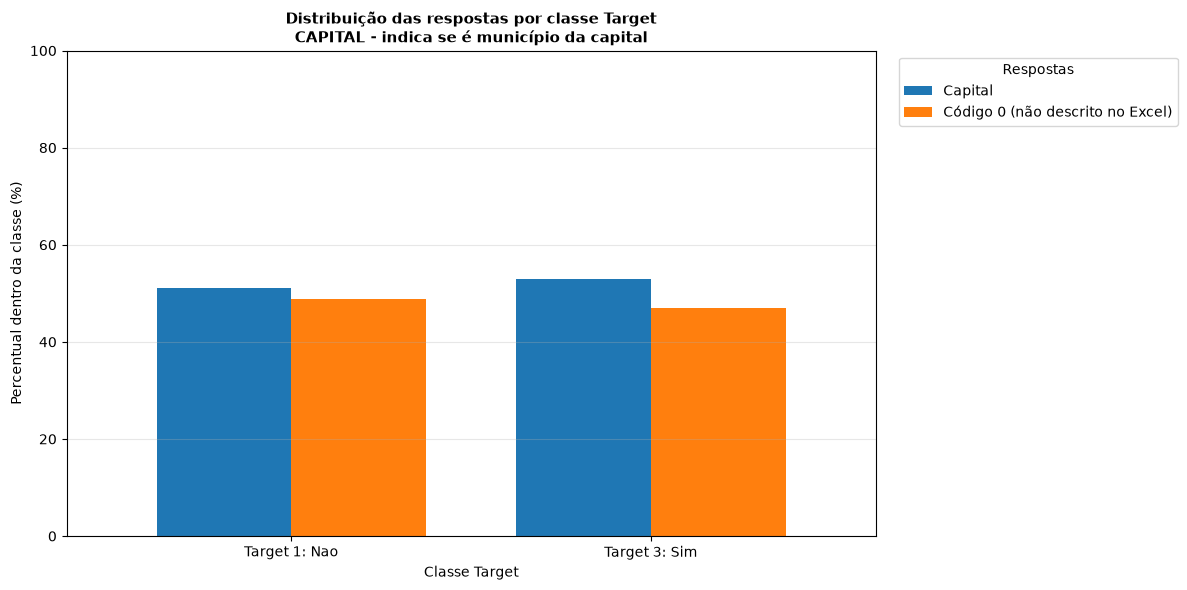


Analisando 2/38: B01001A


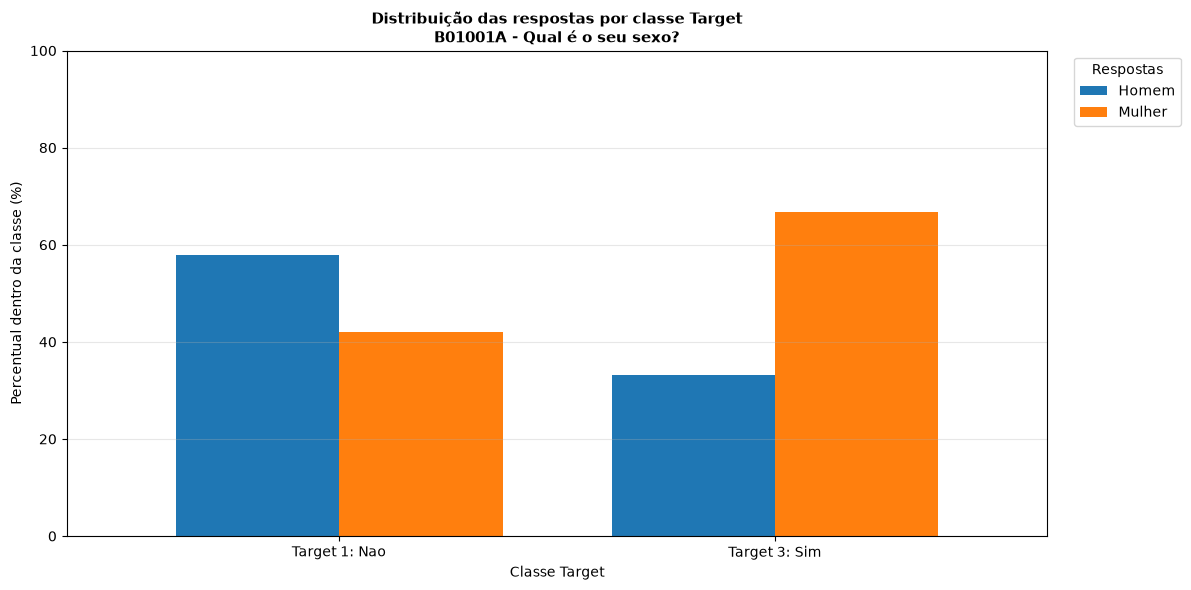


Analisando 3/38: IDADE_AGREG


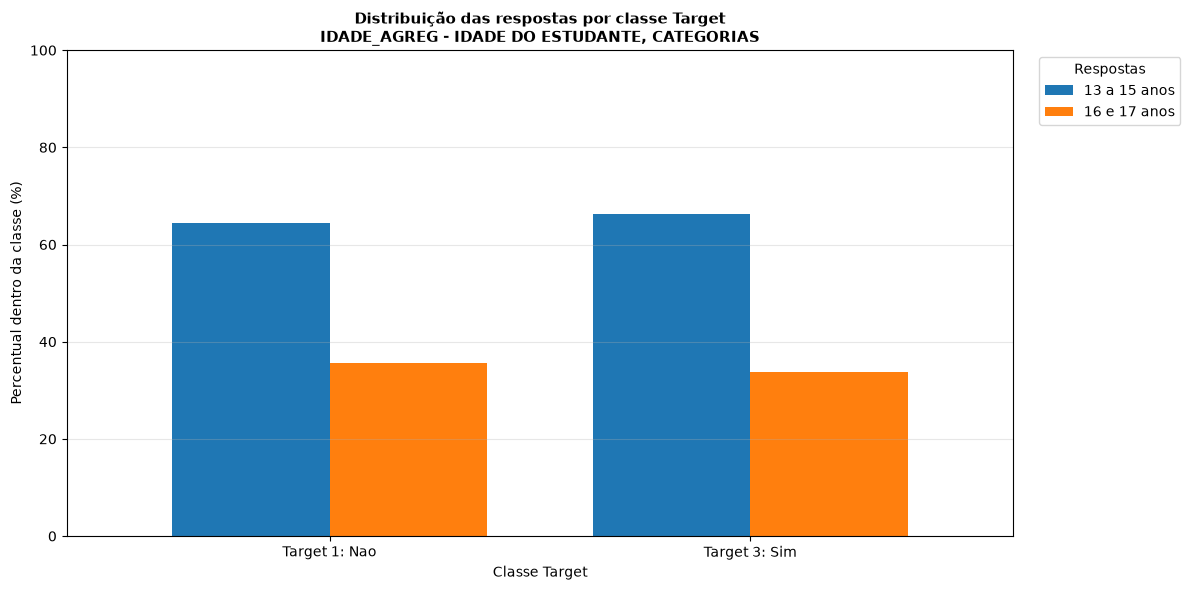


Analisando 4/38: B01002


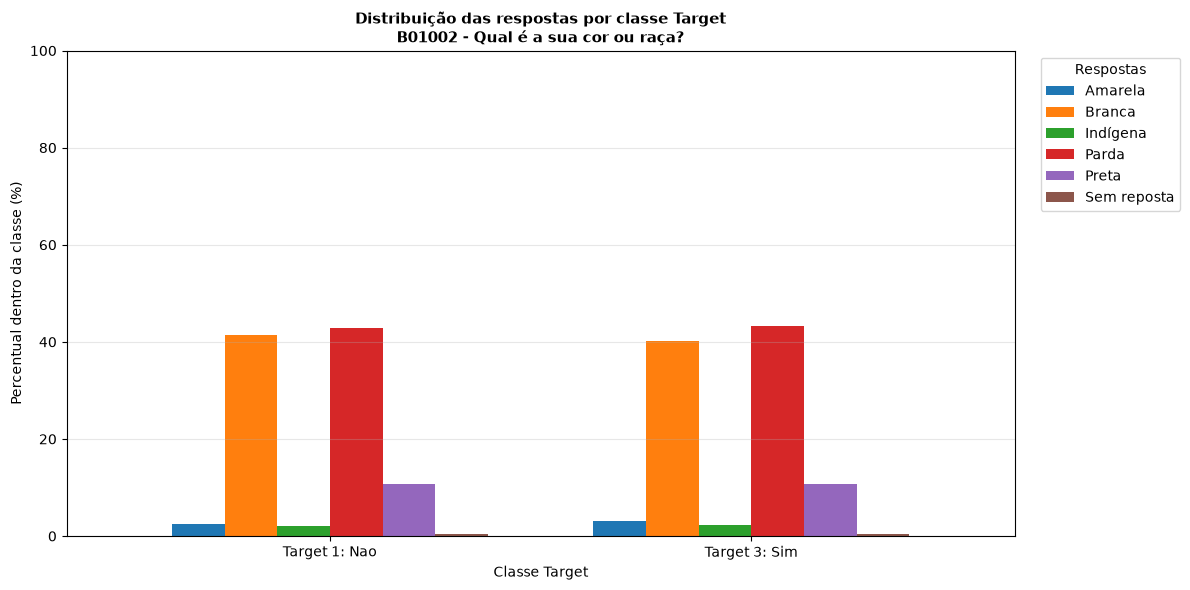


Analisando 5/38: B01006


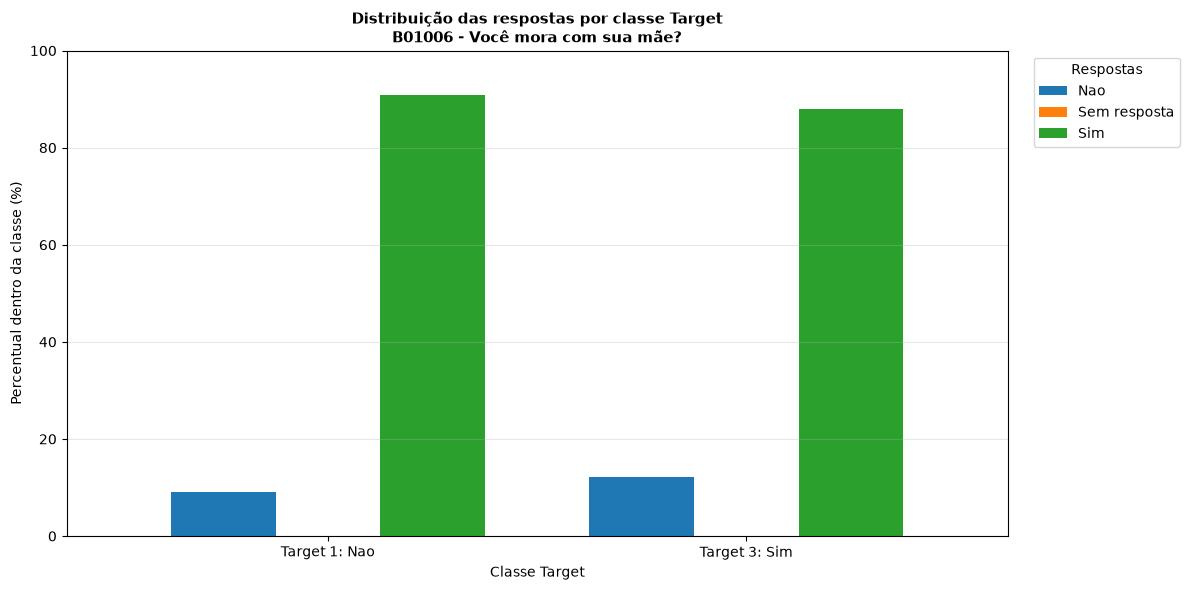


Analisando 6/38: B01007


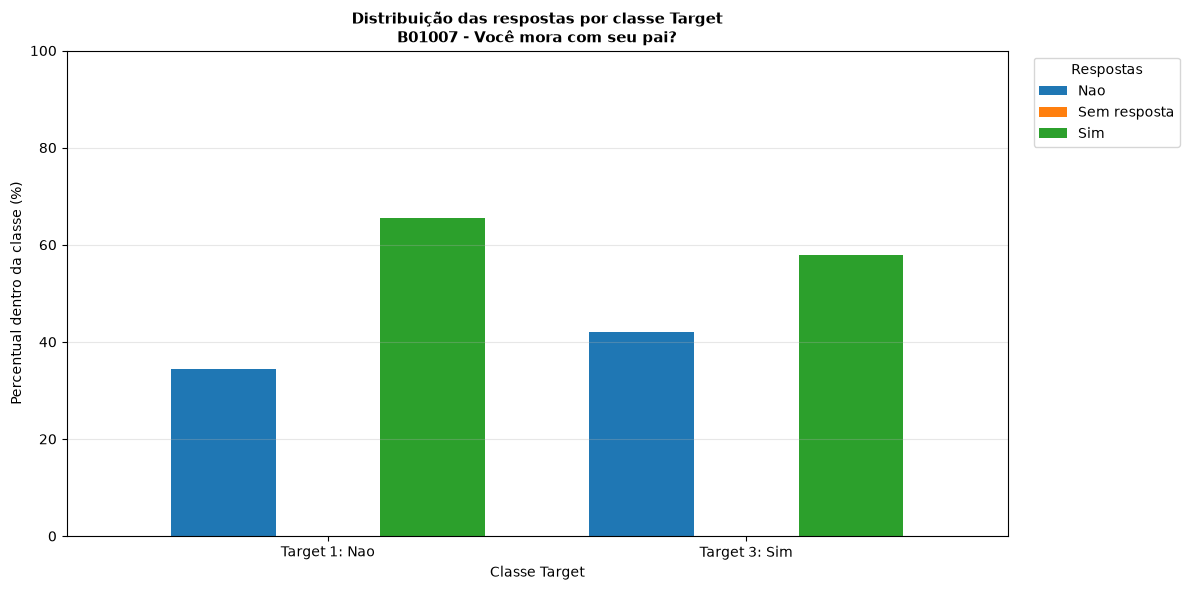


Analisando 7/38: B01015B


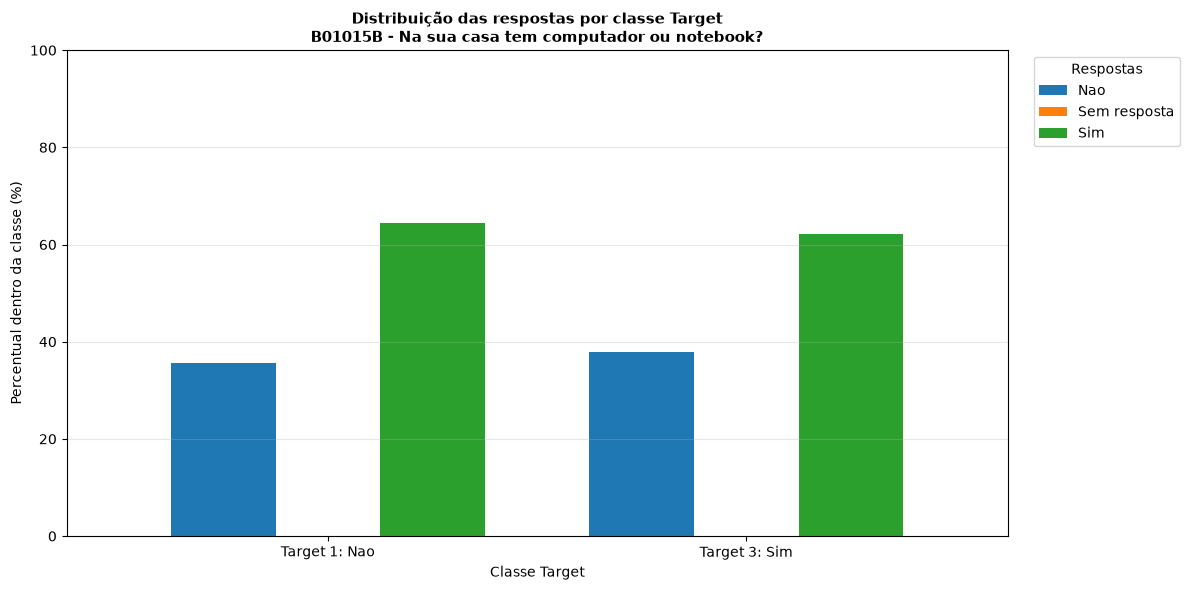


Analisando 8/38: B01016


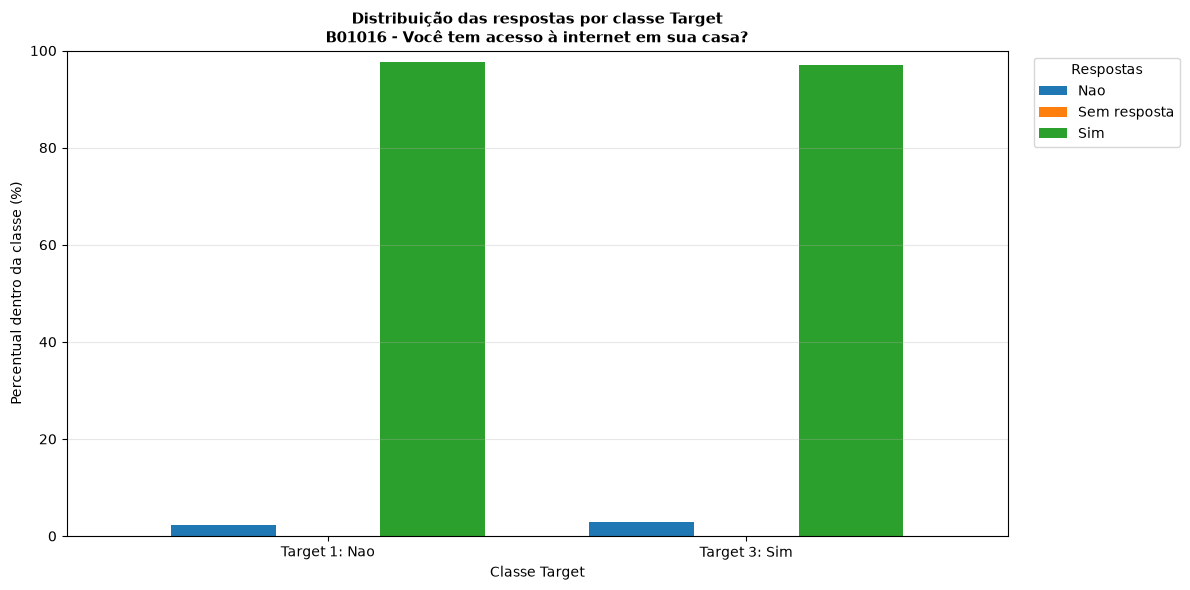


Analisando 9/38: B03006B


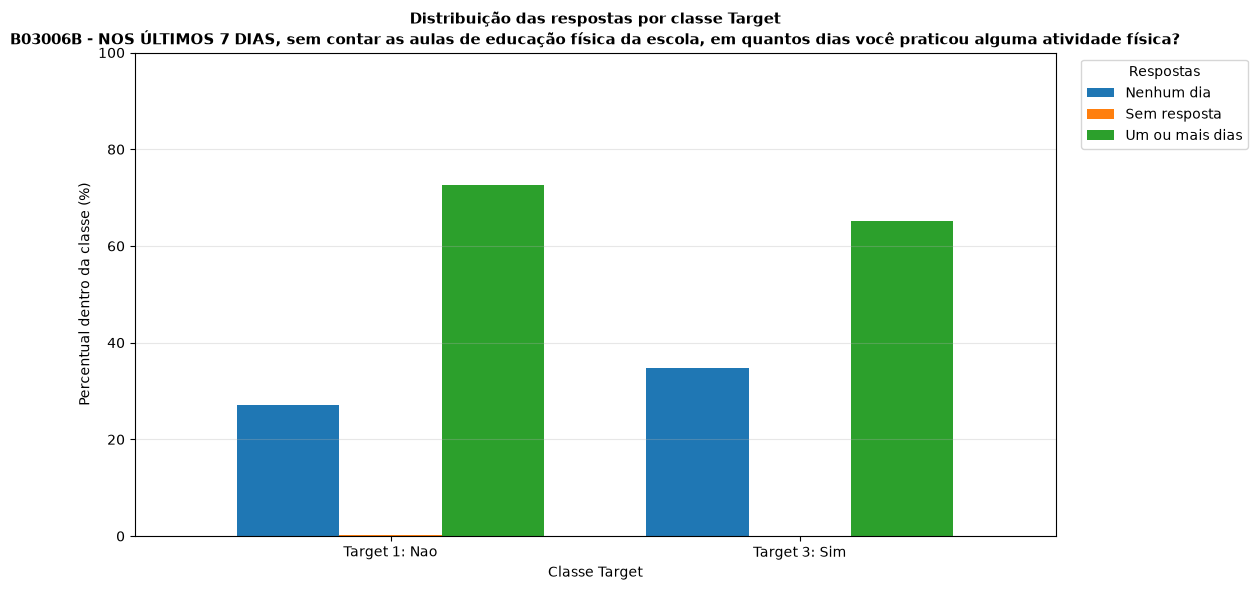


Analisando 10/38: B03010C


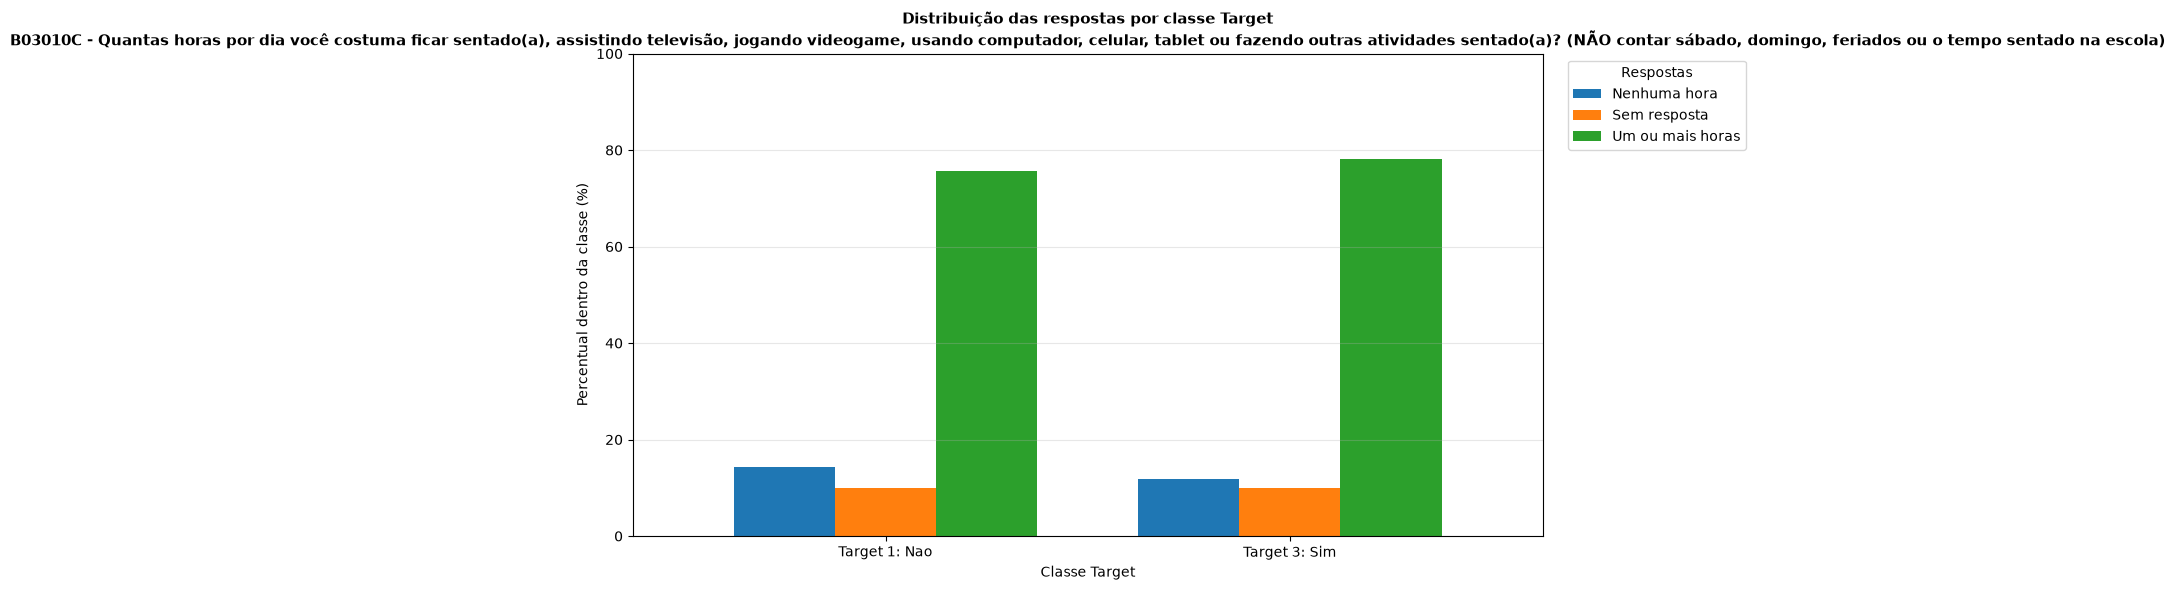


Analisando 11/38: B05002A


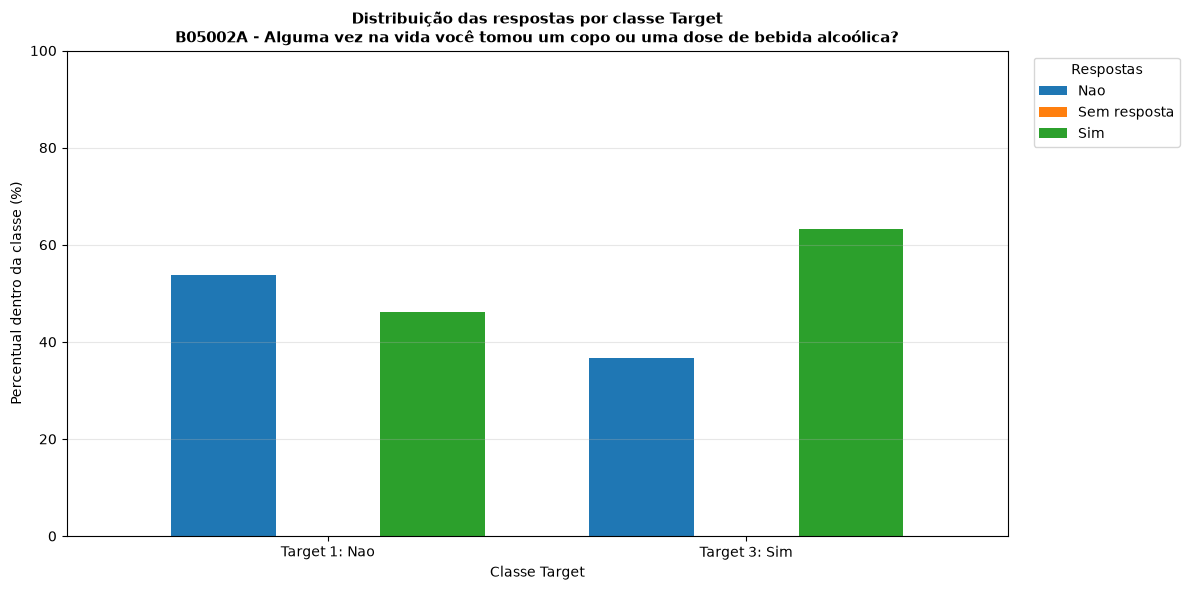


Analisando 12/38: B07002


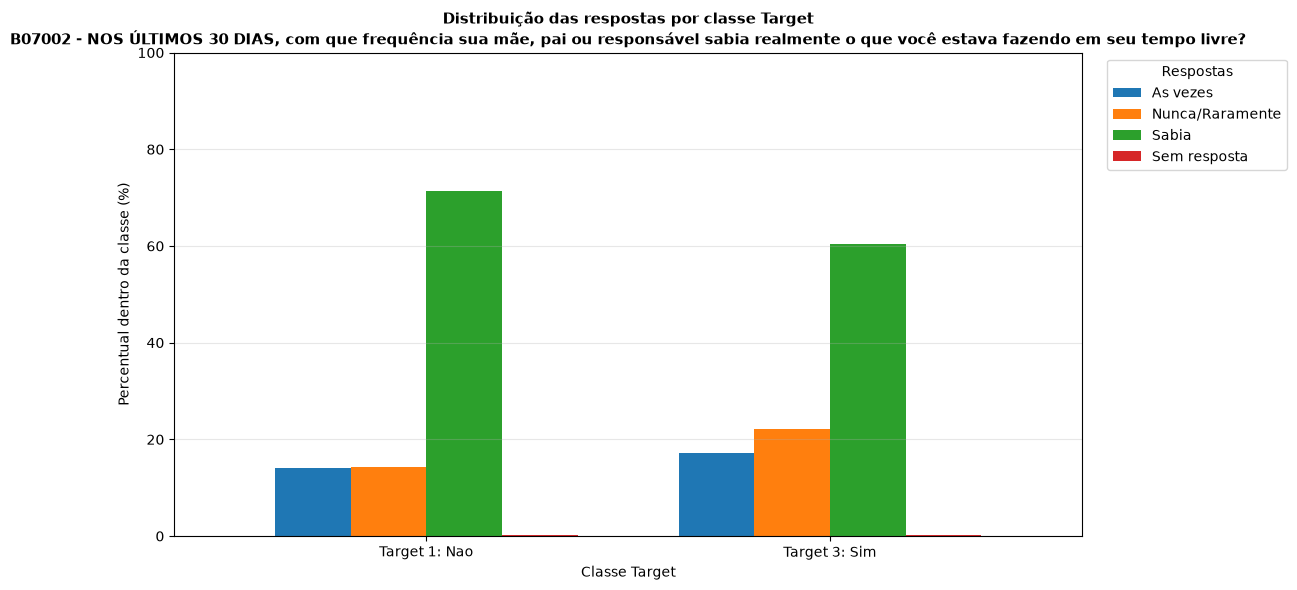


Analisando 13/38: B07004


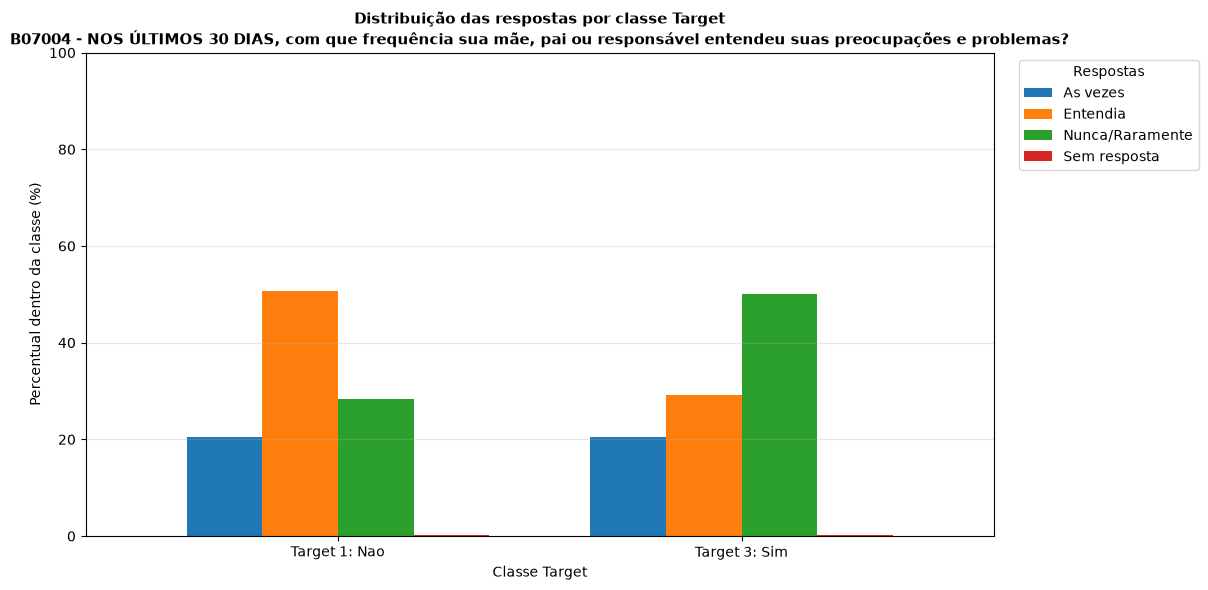


Analisando 14/38: B07005


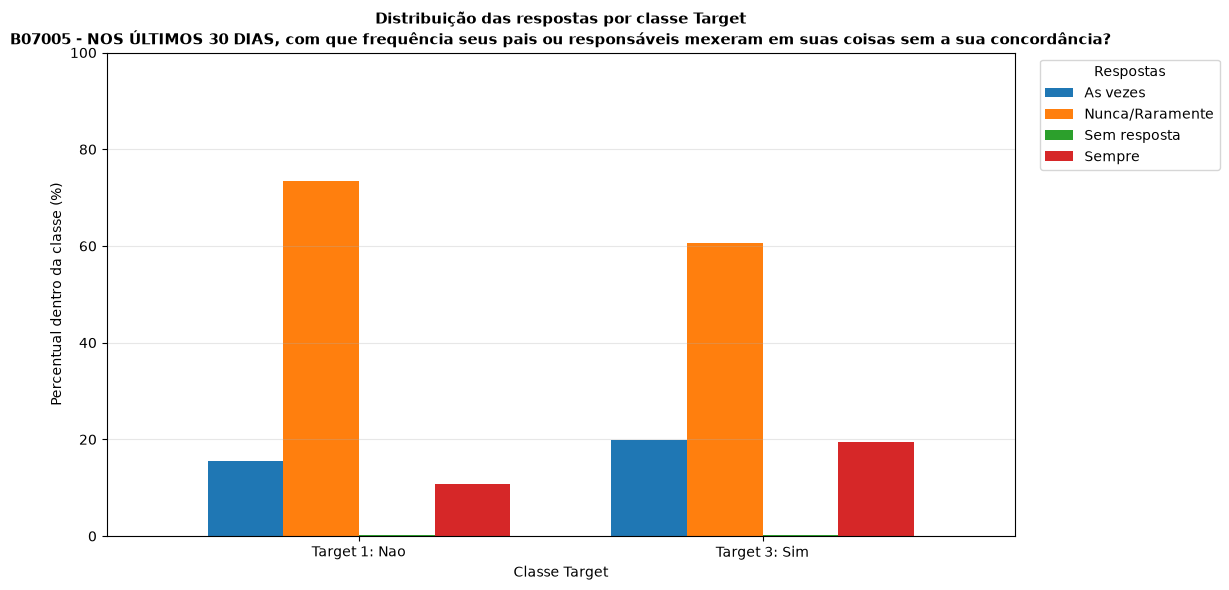


Analisando 15/38: B07006


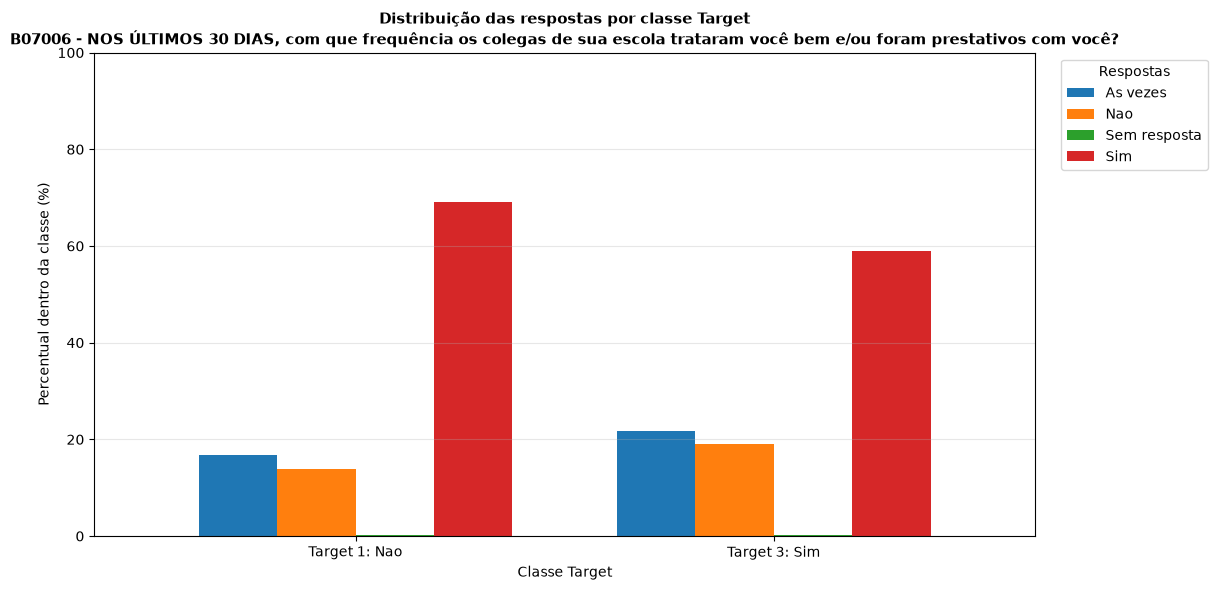


Analisando 16/38: B07007B


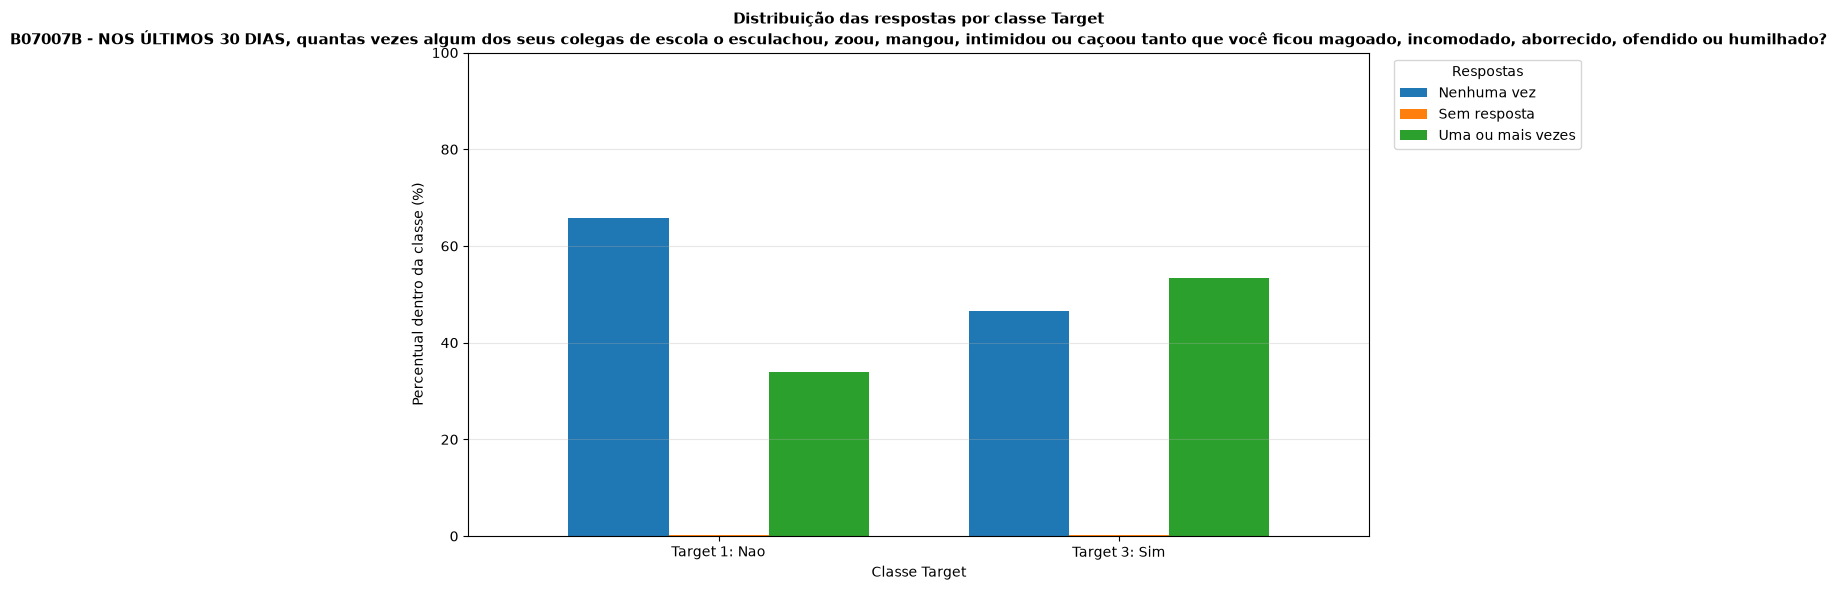


Analisando 17/38: B07011A


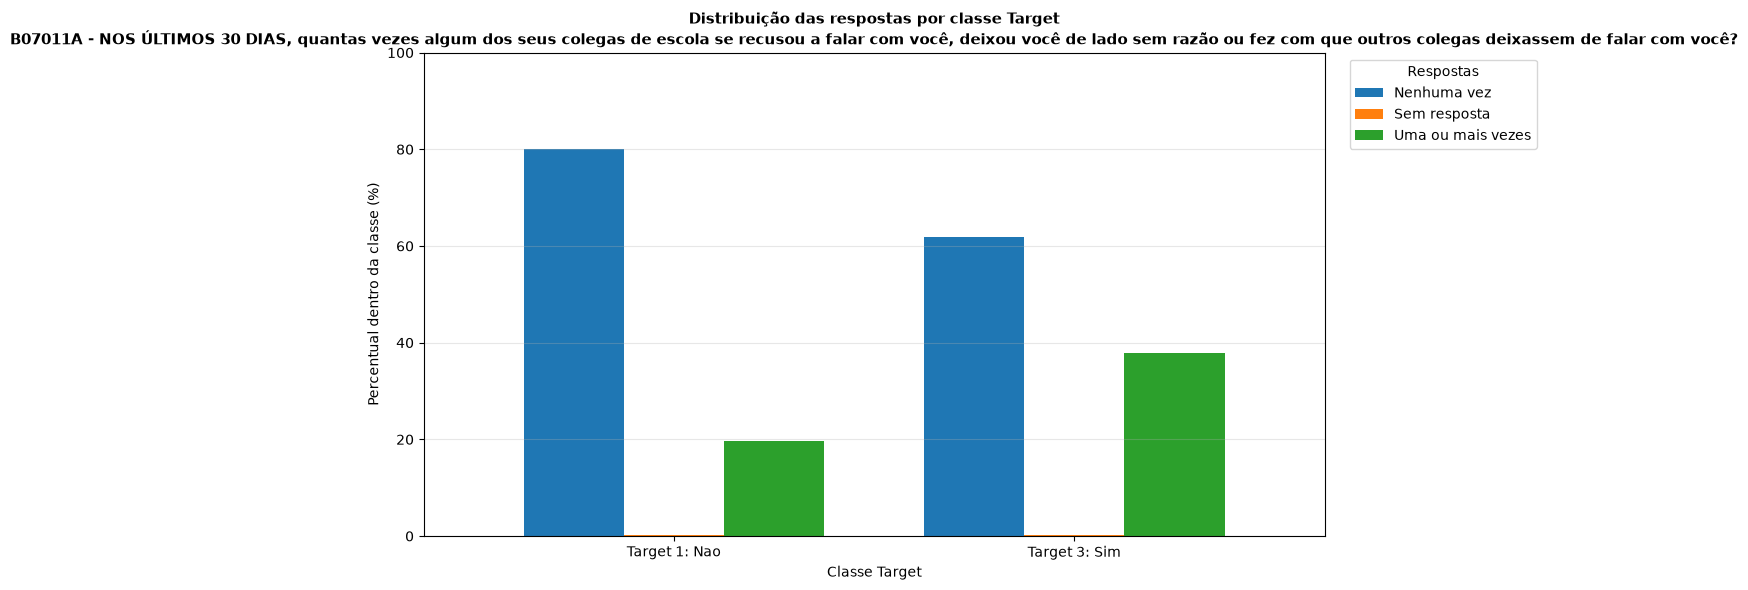


Analisando 18/38: B07012A


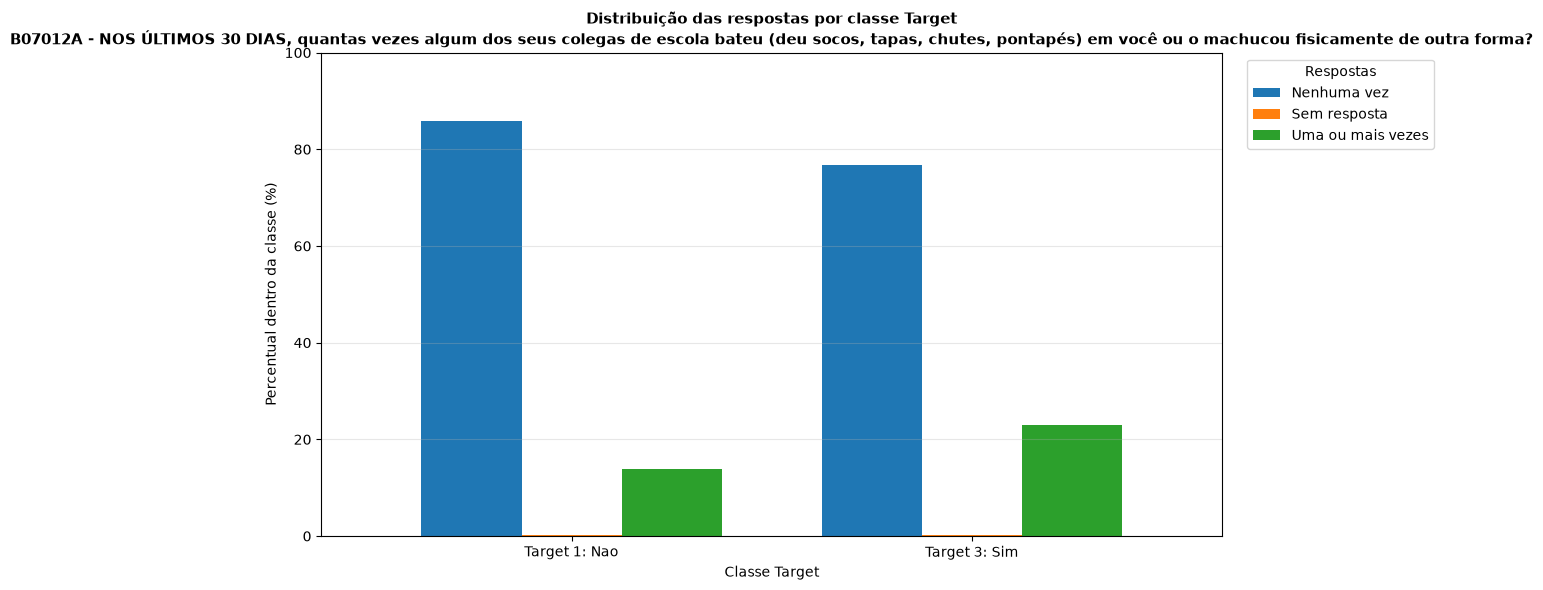


Analisando 19/38: B07013


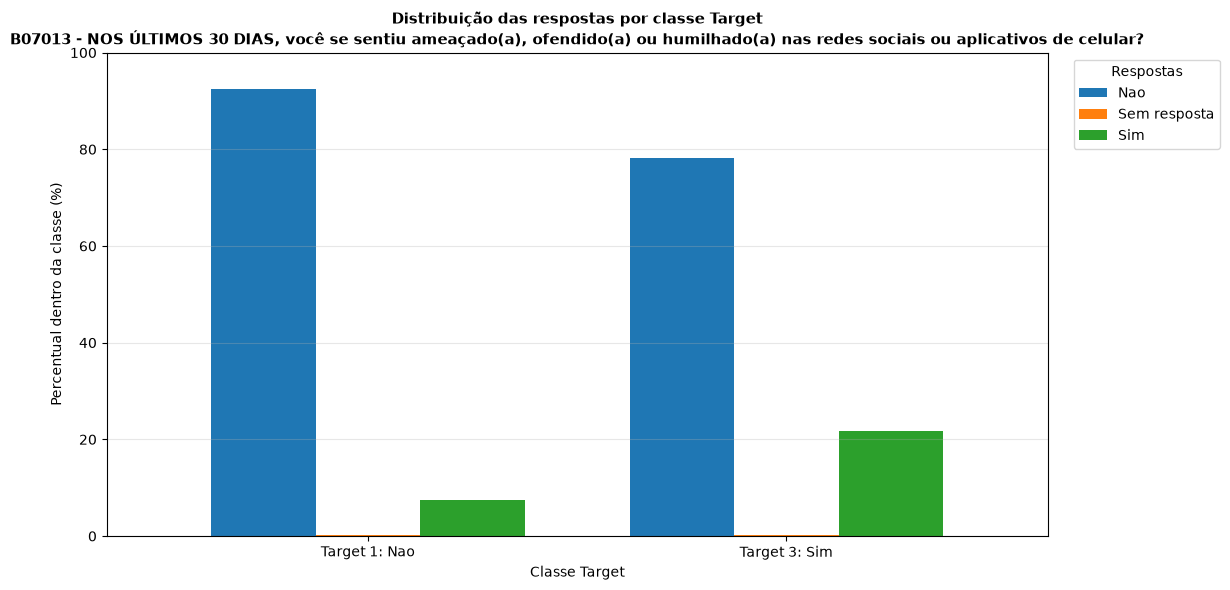


Analisando 20/38: B07009


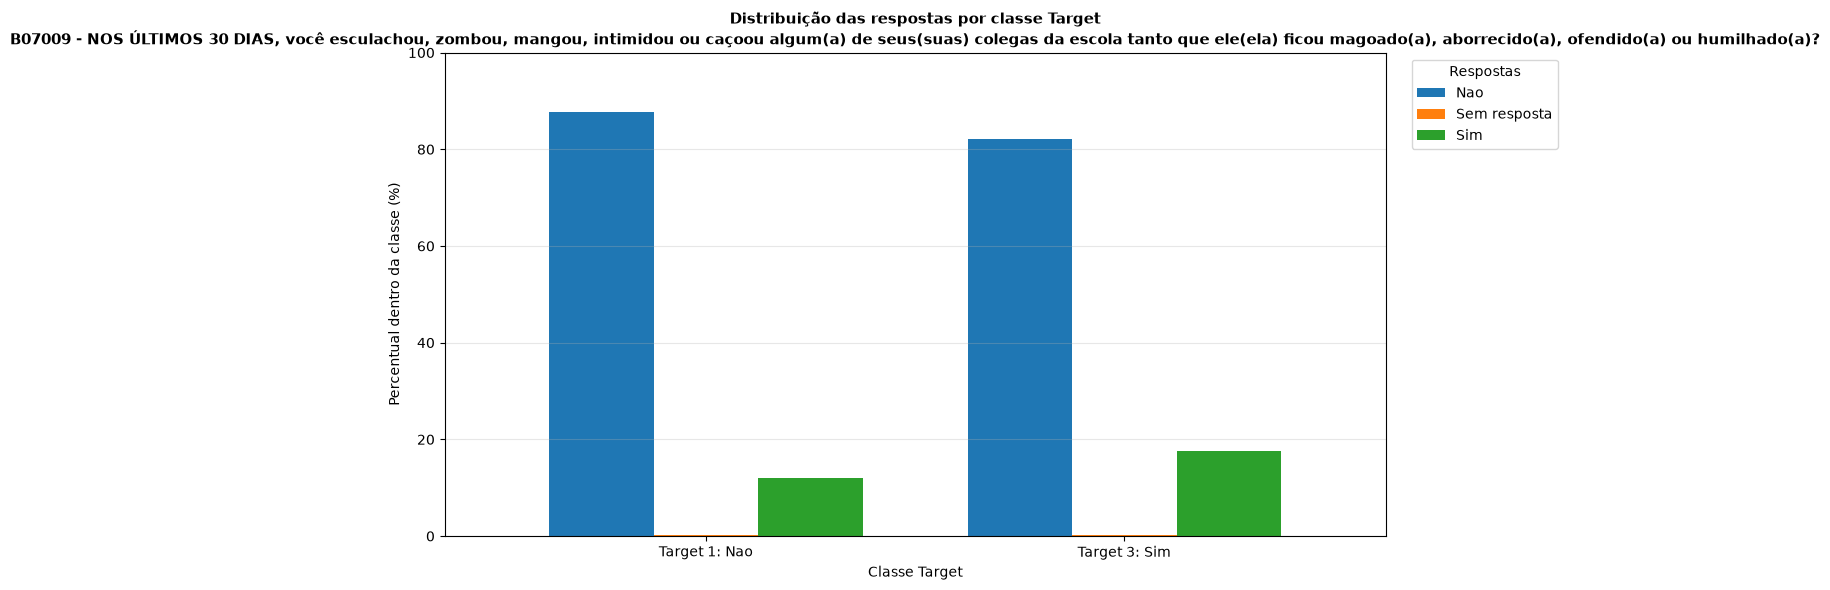


Analisando 21/38: B07016


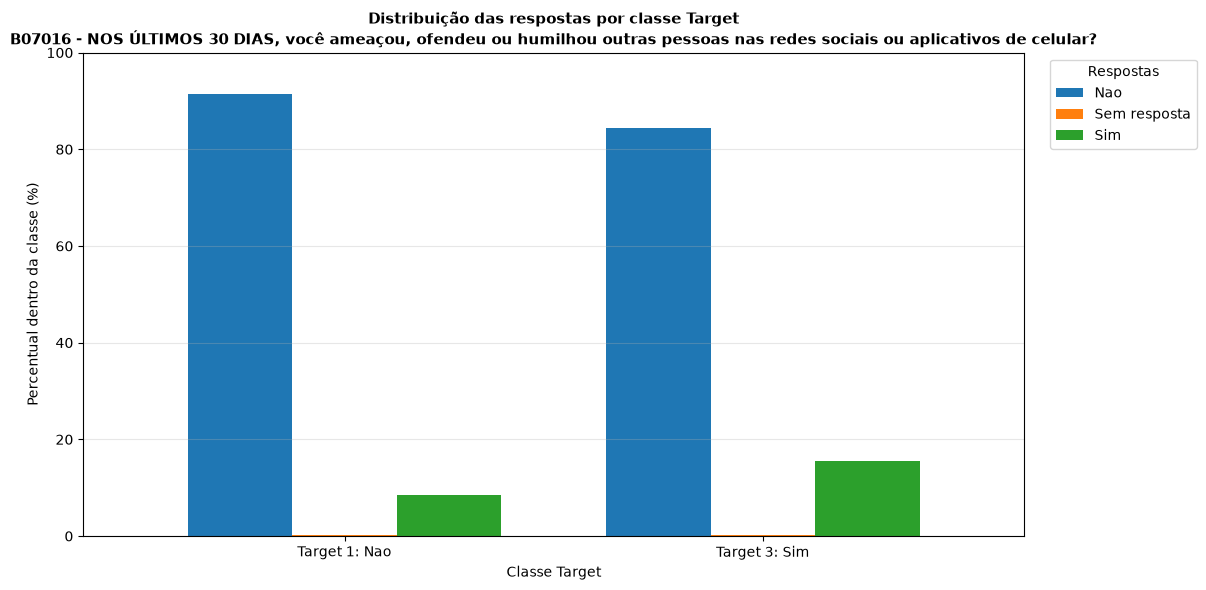


Analisando 22/38: B12003


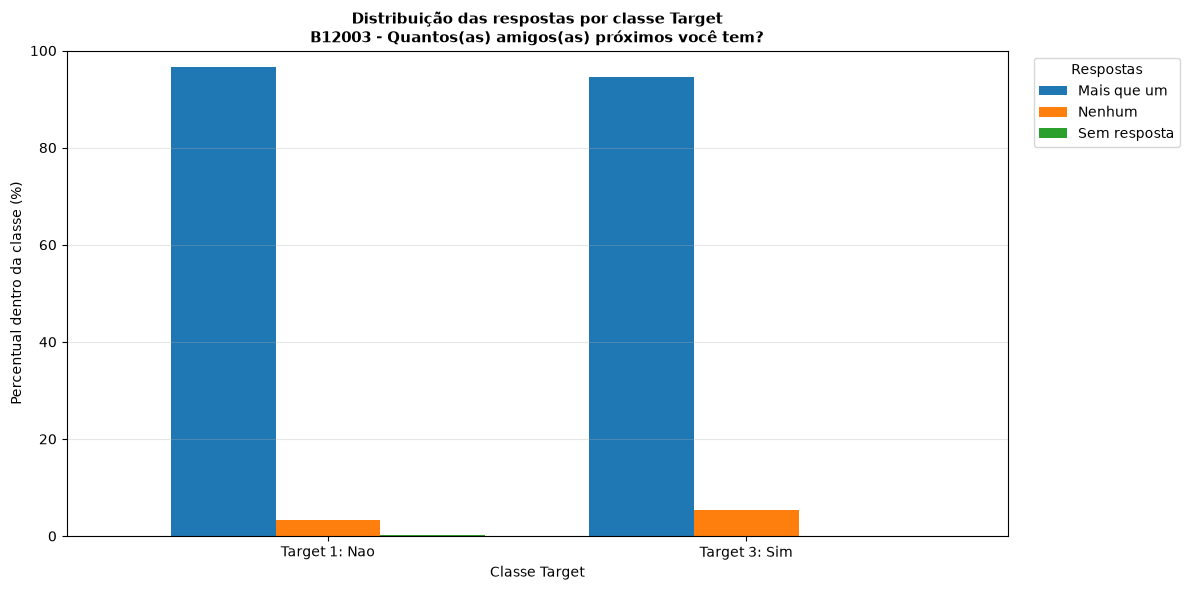


Analisando 23/38: B12004


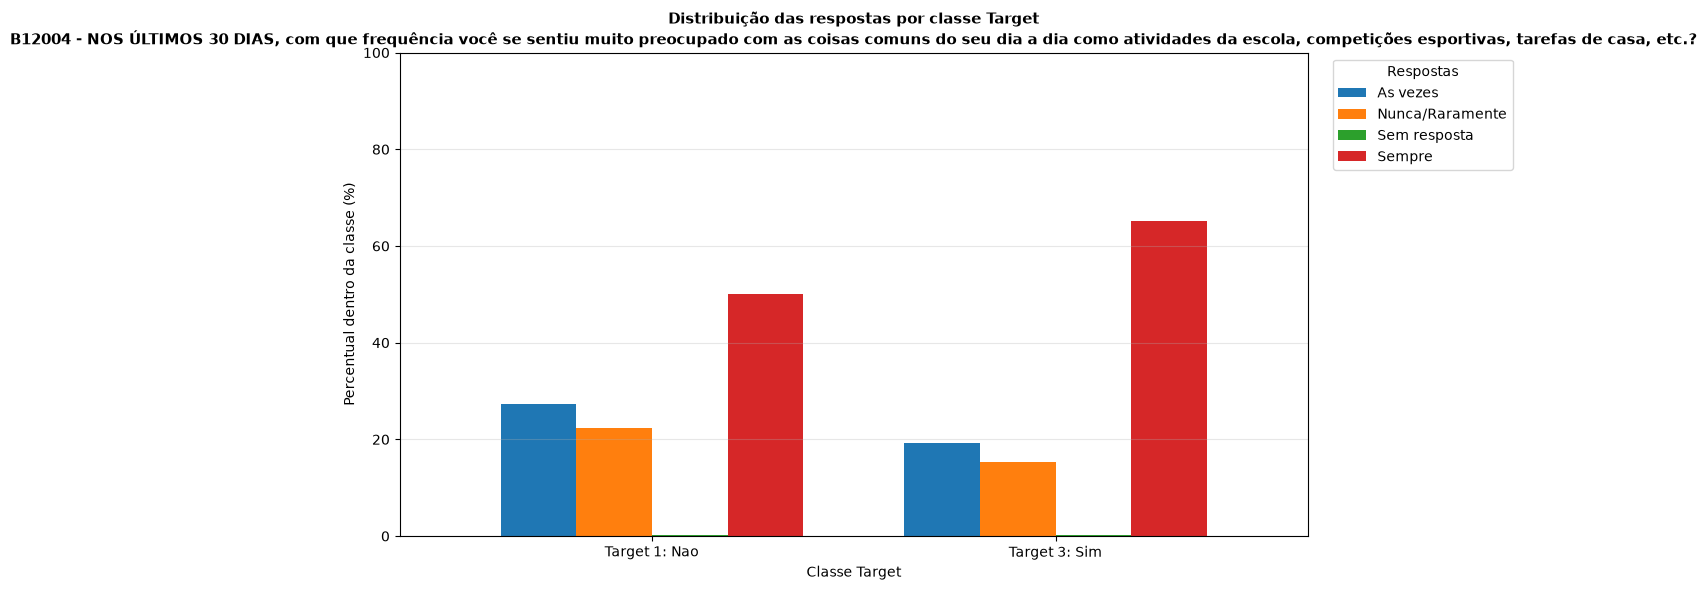


Analisando 24/38: B12005


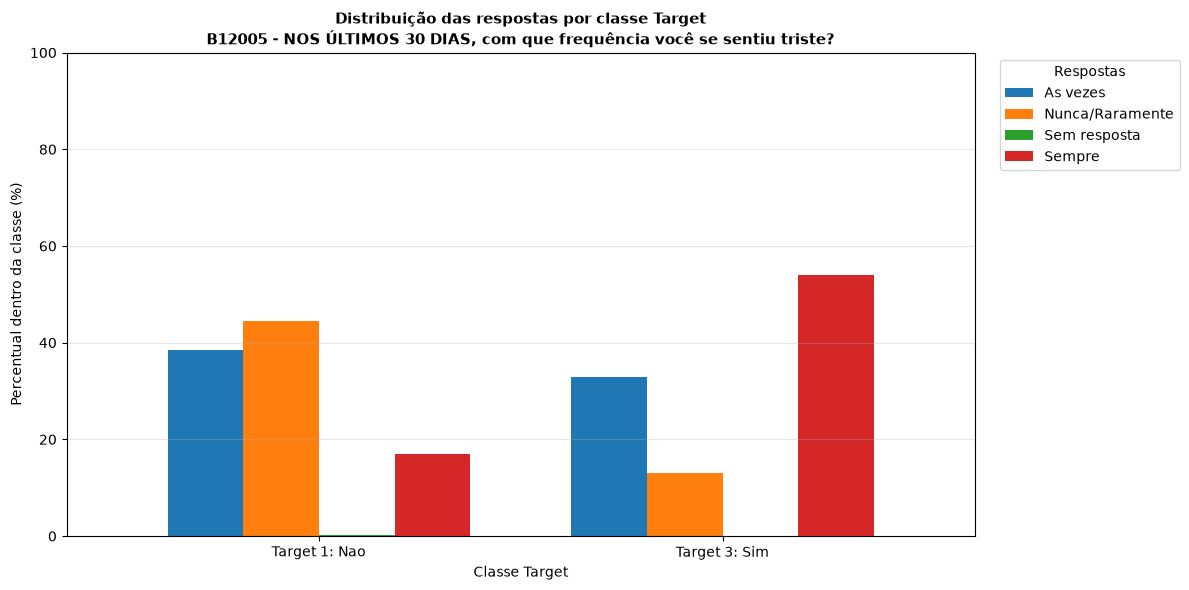


Analisando 25/38: B12006


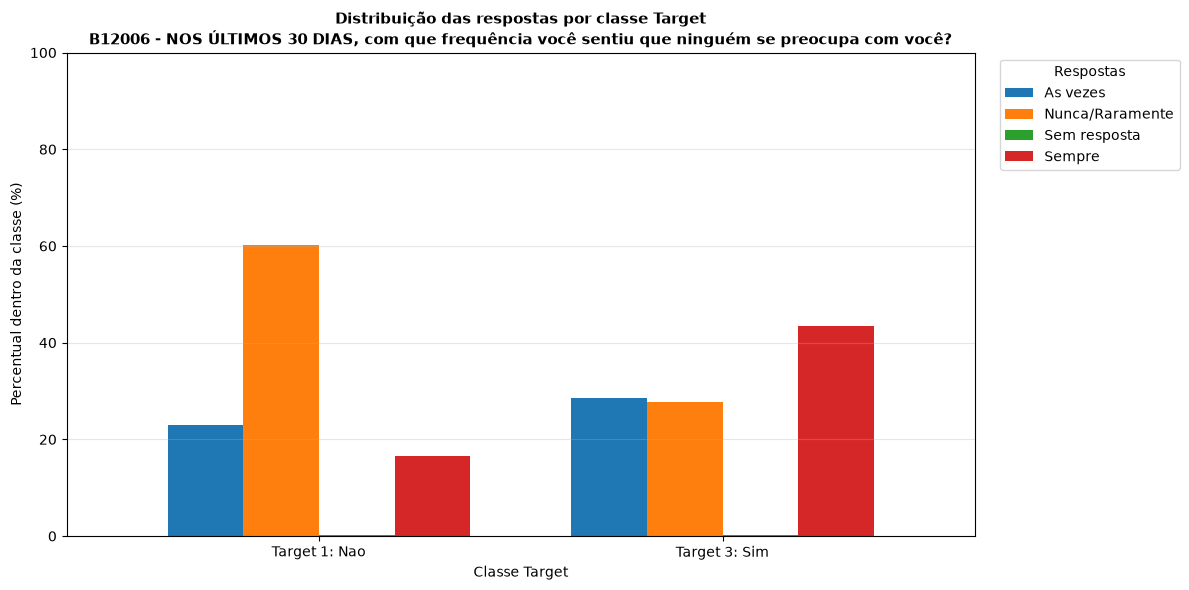


Analisando 26/38: B12007


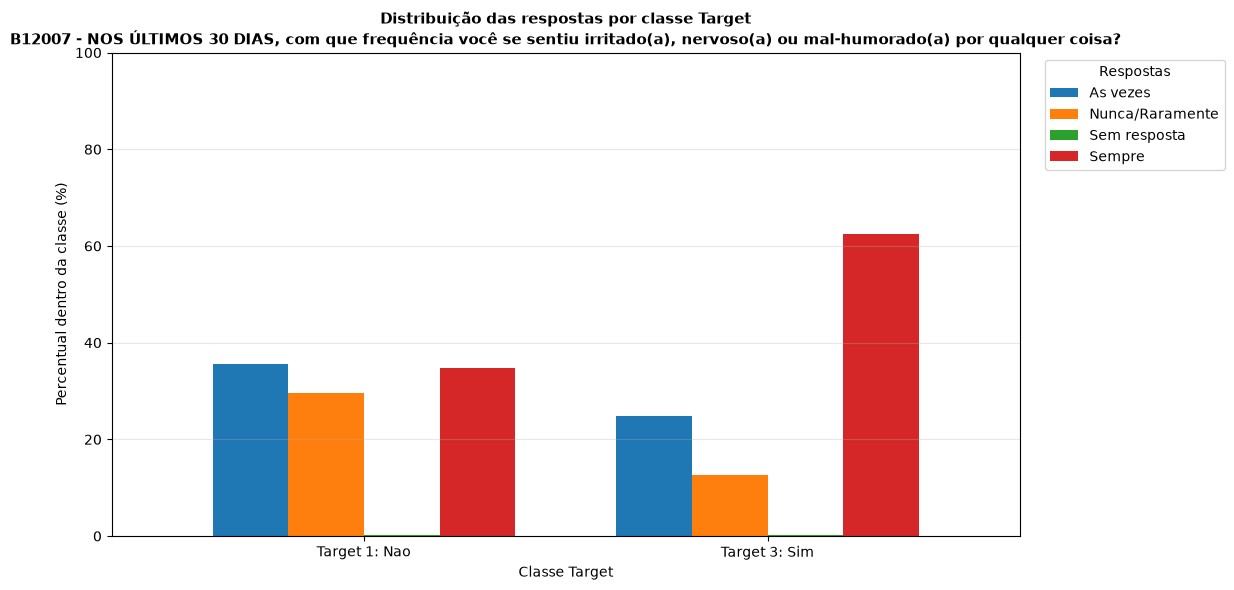


Analisando 27/38: B12008


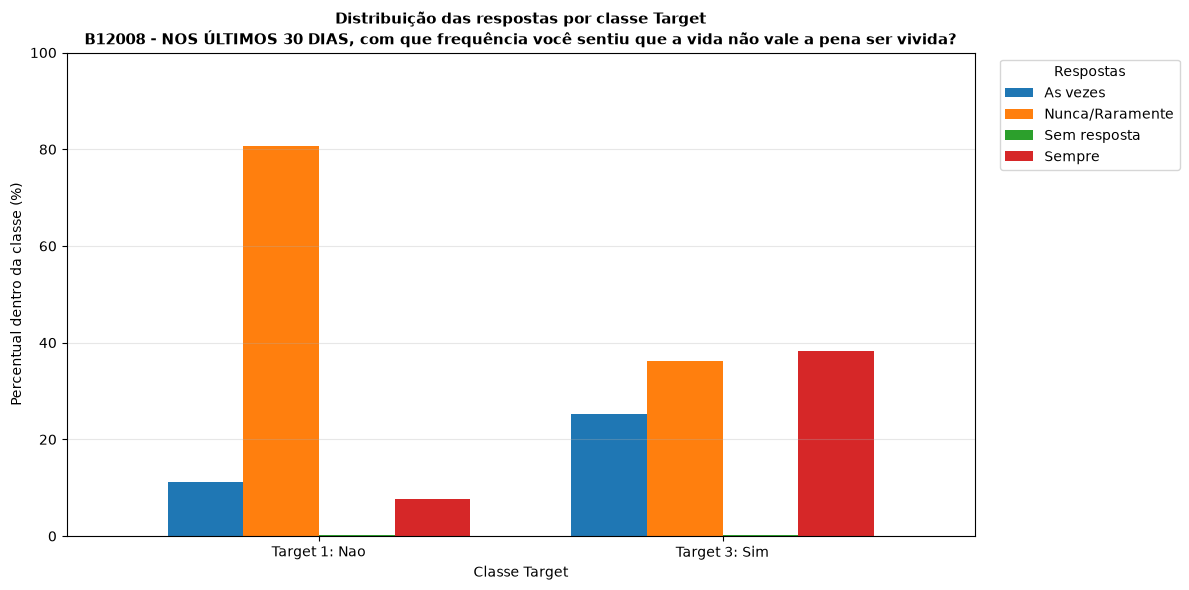


Analisando 28/38: B09001


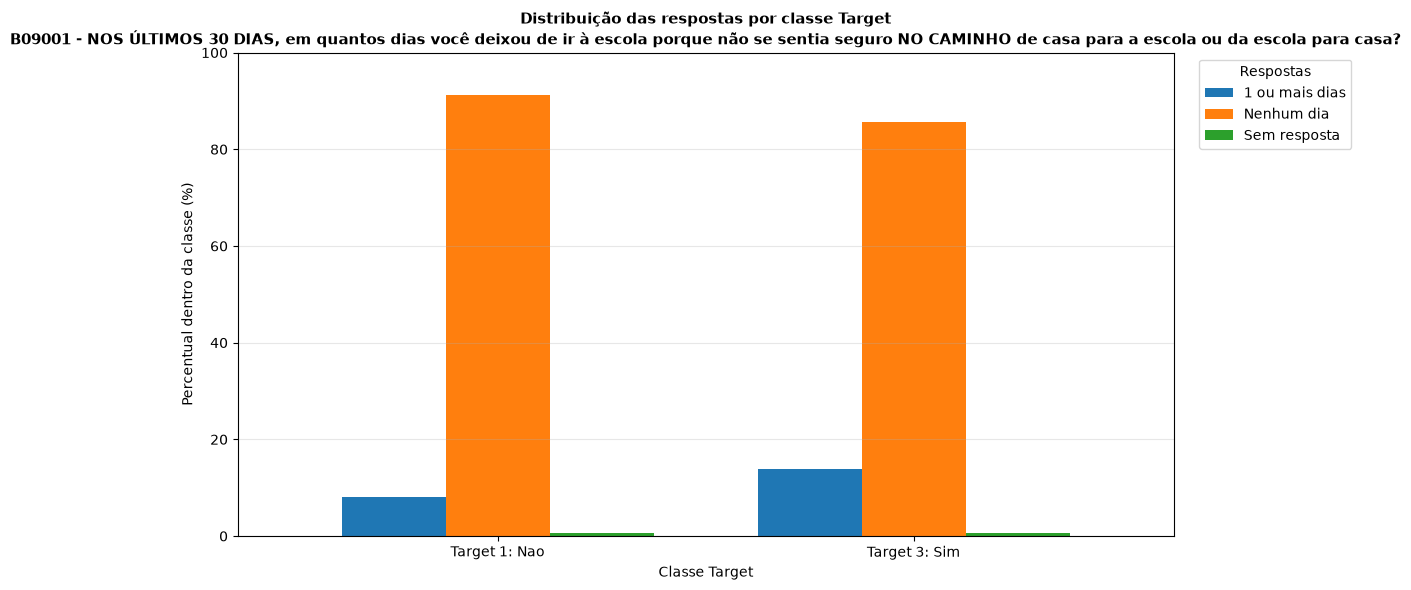


Analisando 29/38: B09002


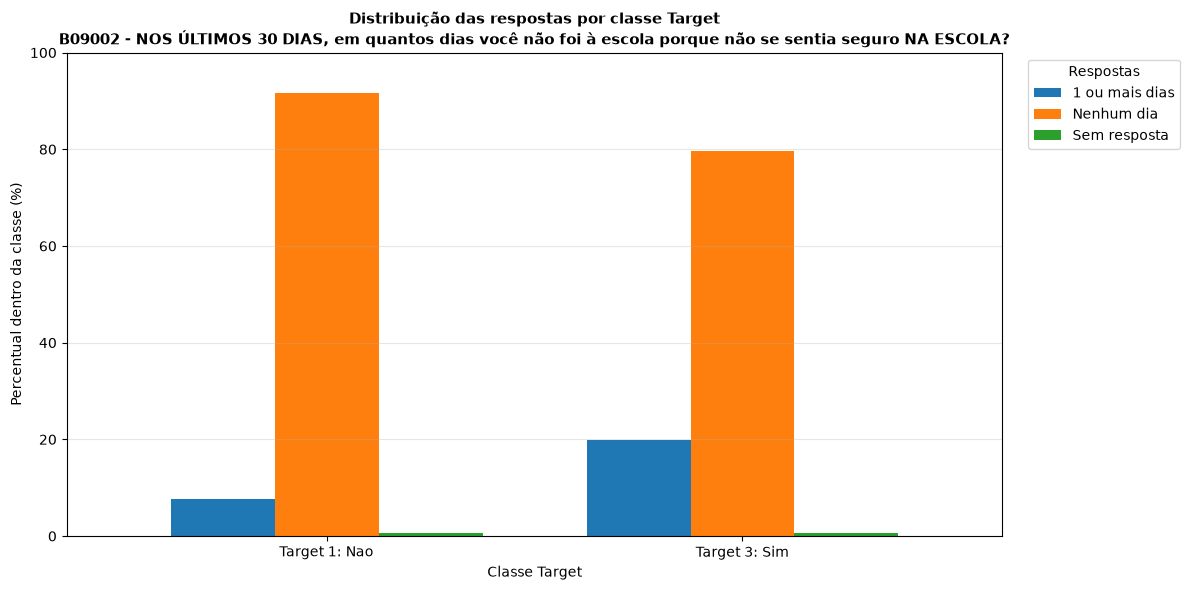


Analisando 30/38: B09003A


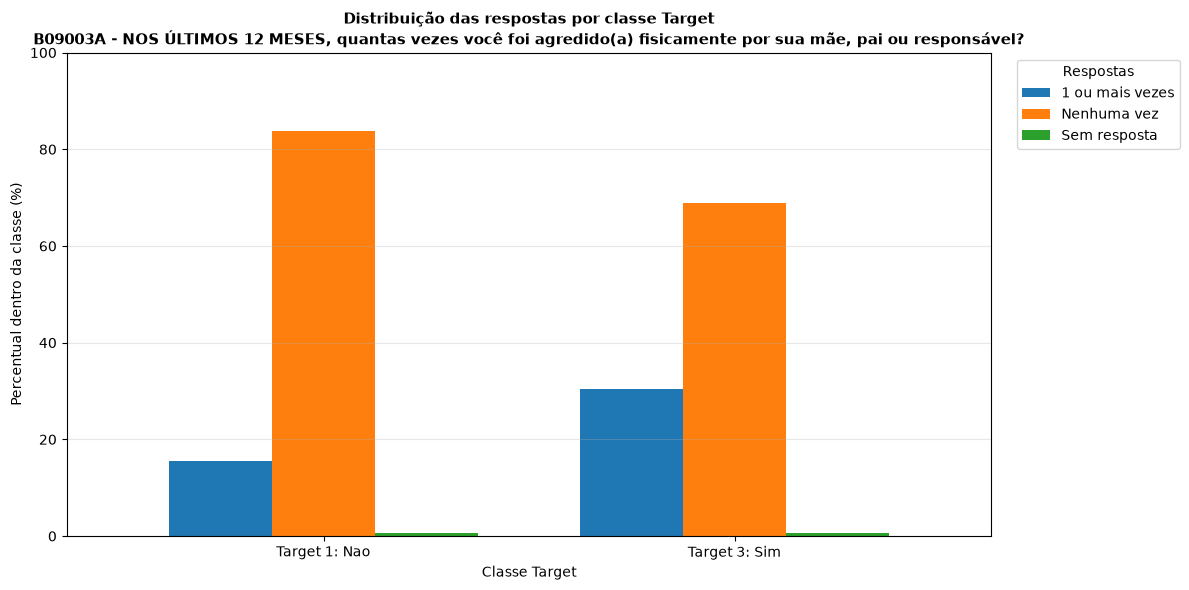


Analisando 31/38: B09010A1


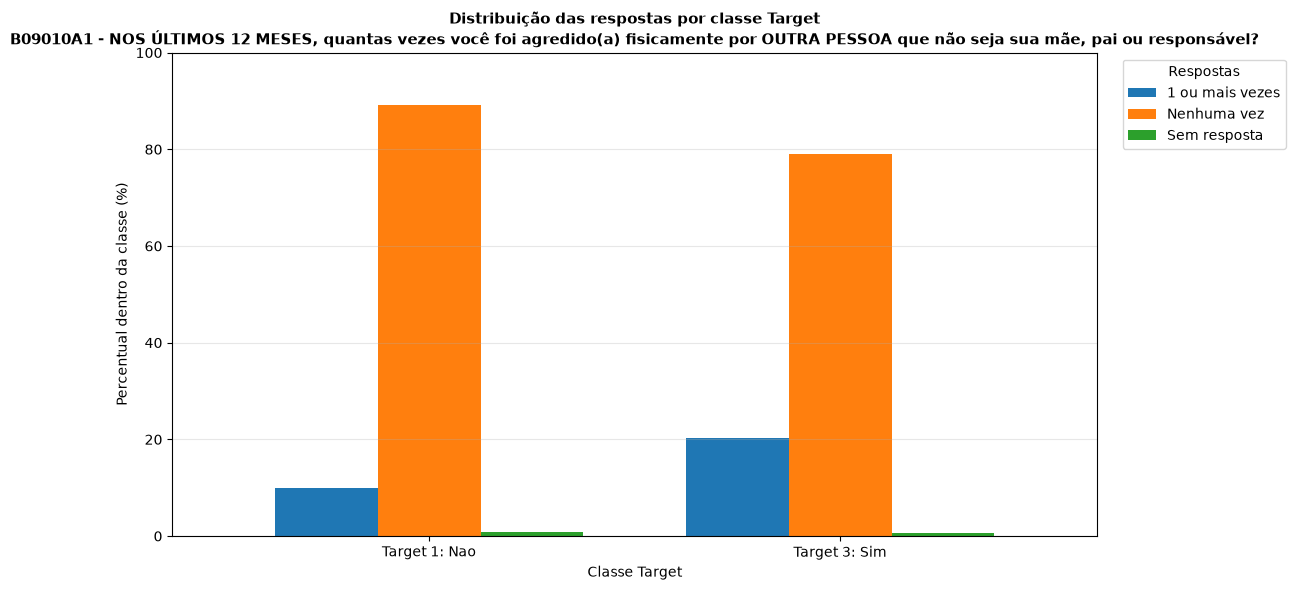


Analisando 32/38: B09016A1


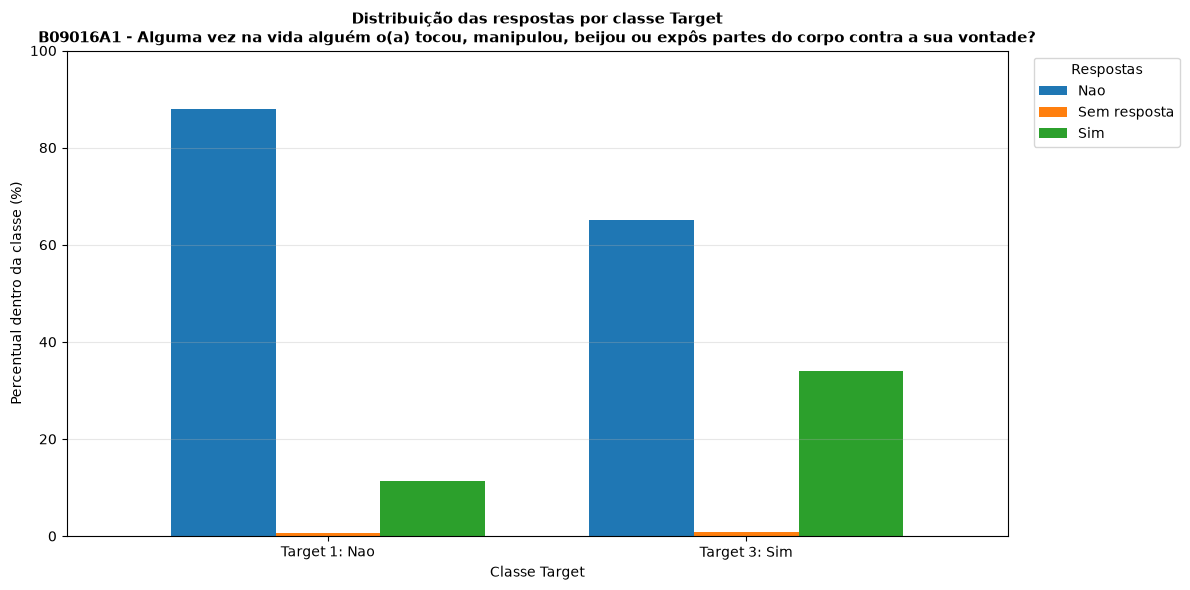


Analisando 33/38: B09016A2


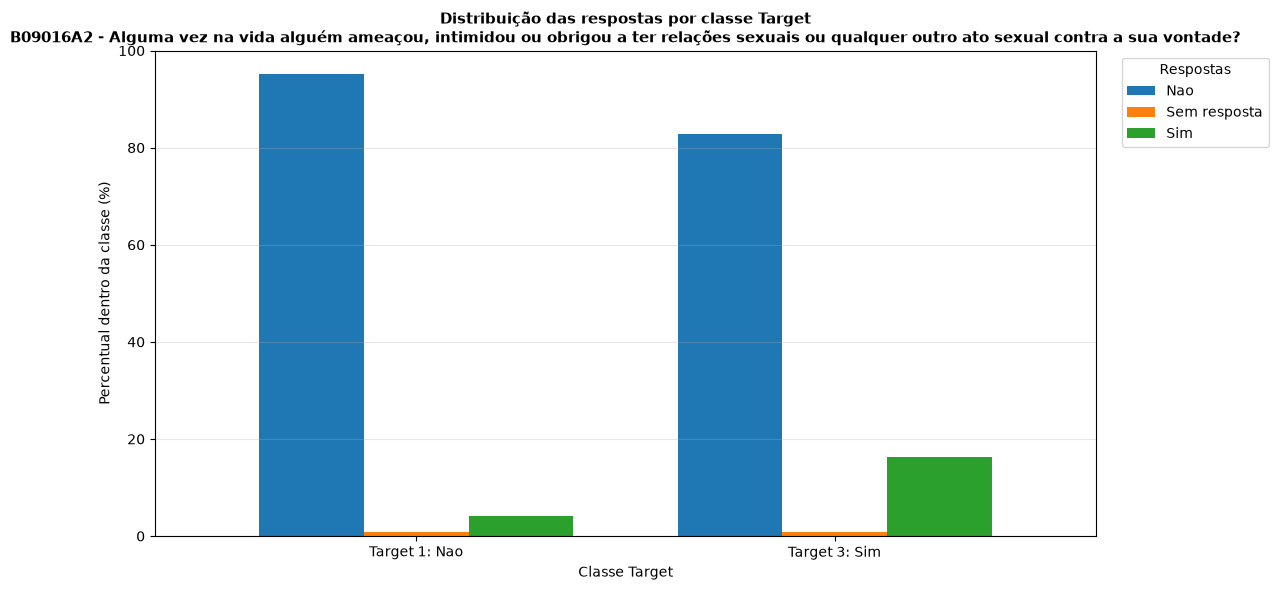


Analisando 34/38: E01P8505


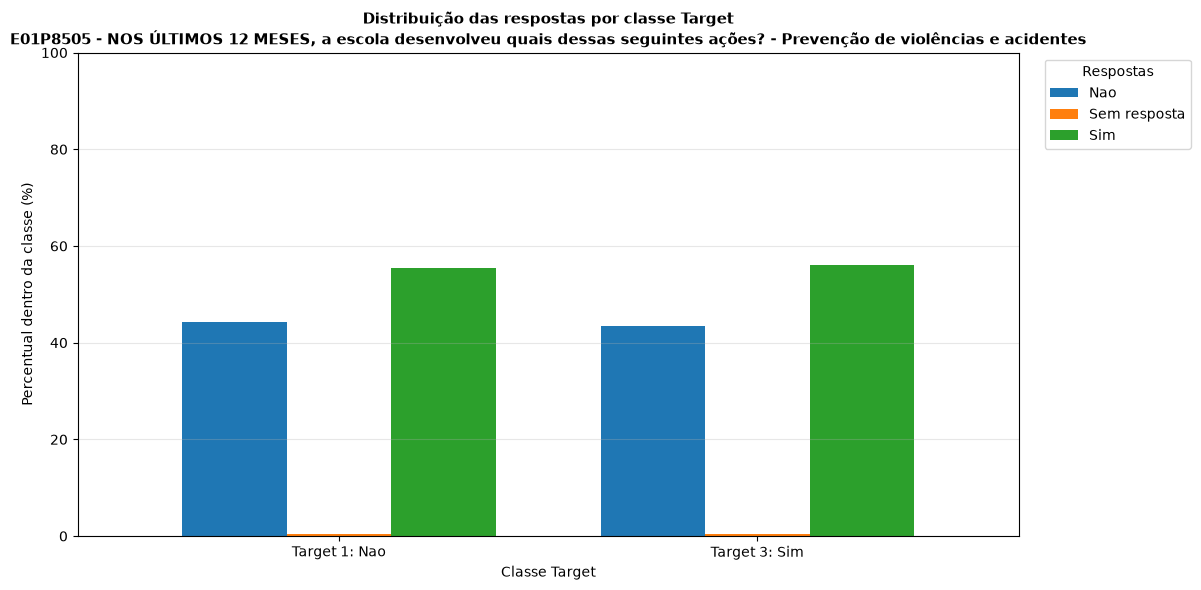


Analisando 35/38: E01P8510


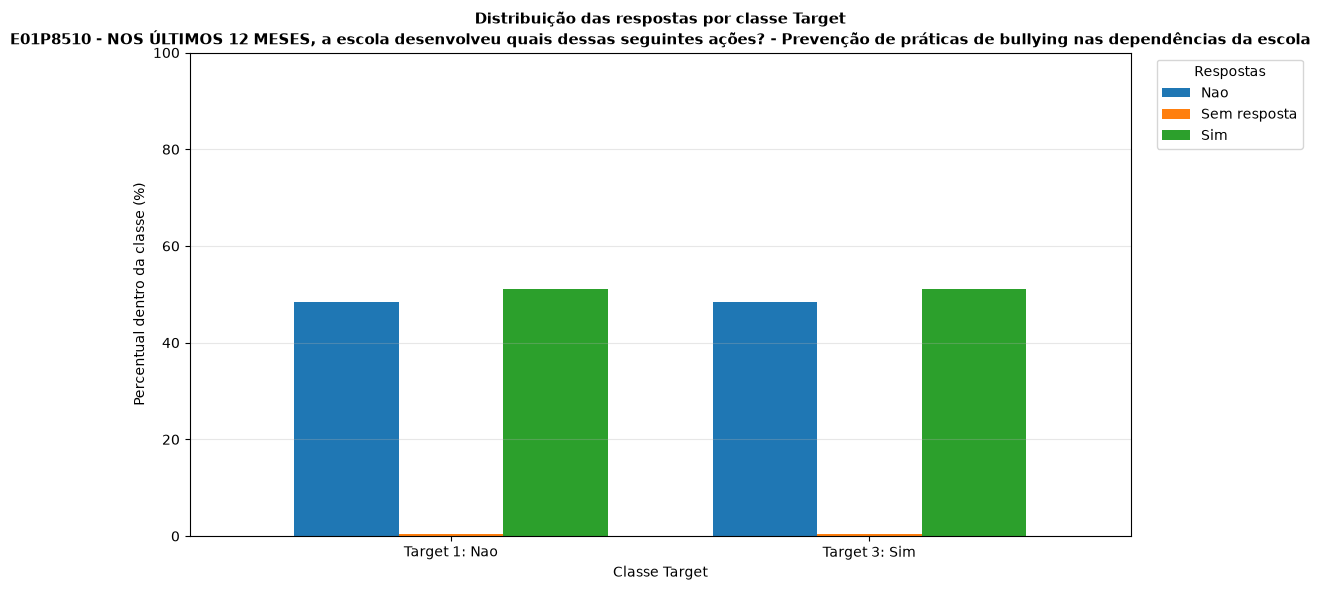


Analisando 36/38: E01P117


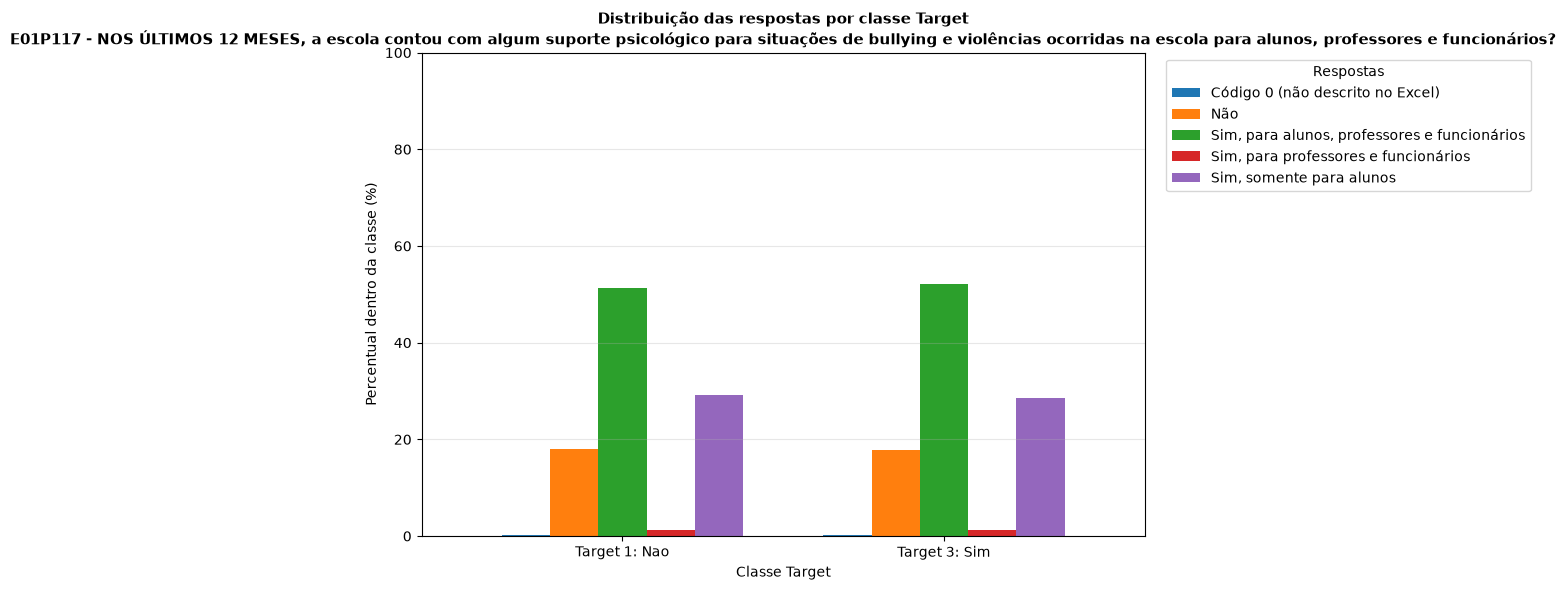


Analisando 37/38: E01P11801


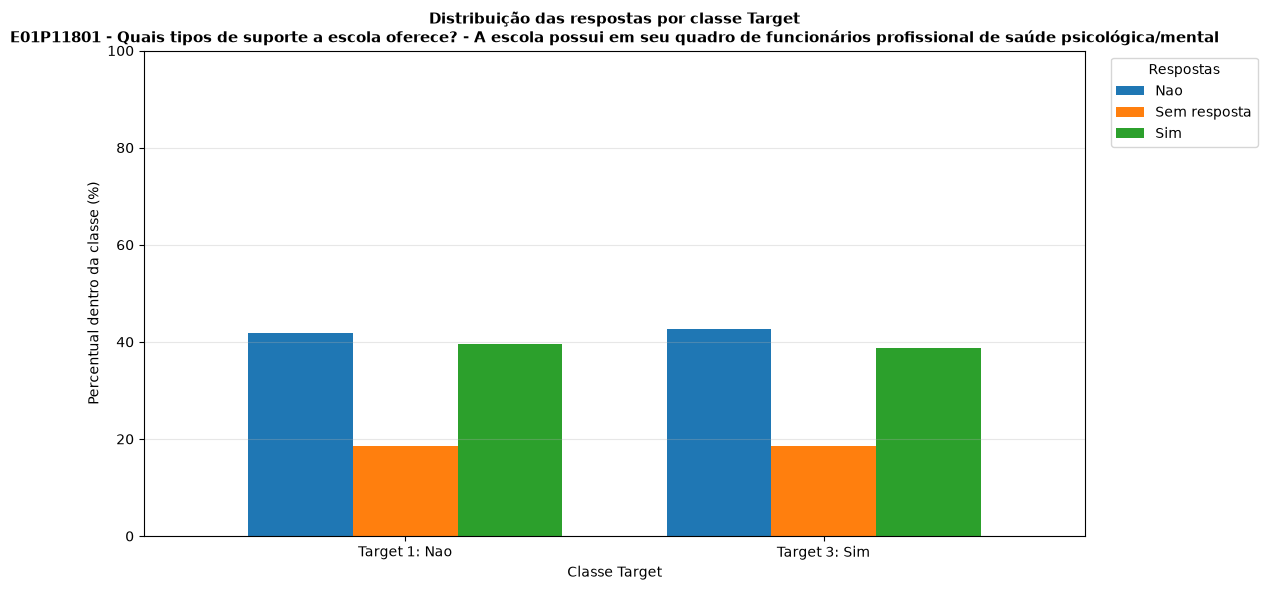


Analisando 38/38: E01P11802


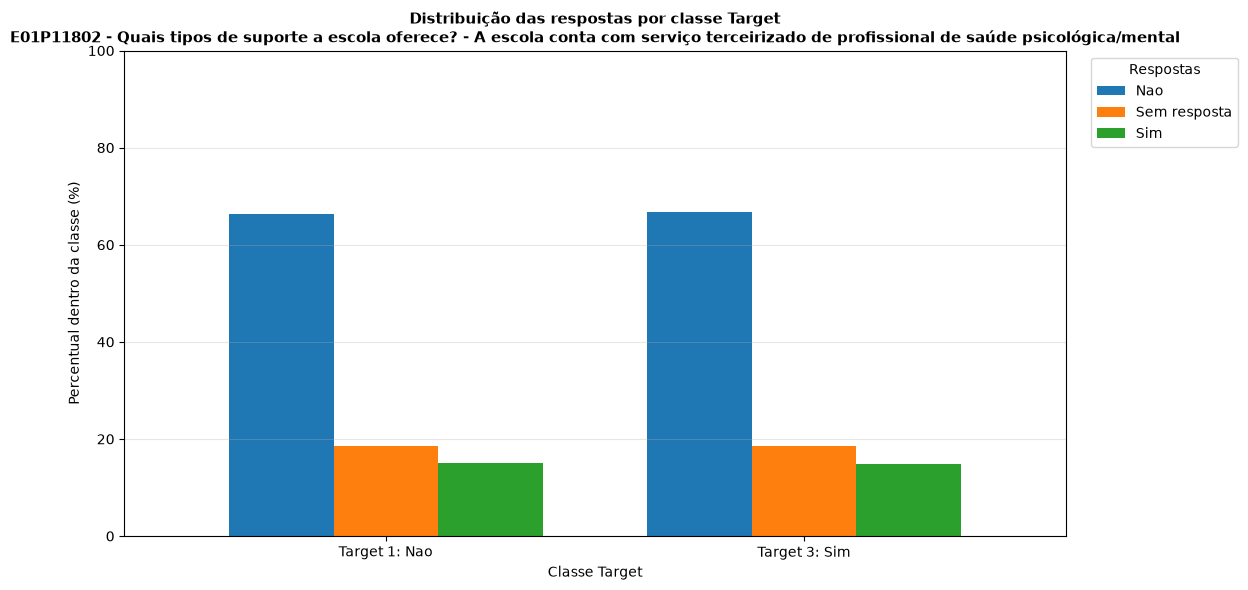



DISTRIBUIÇÃO DAS RESPOSTAS POR CLASSE TARGET


,Variavel,Codigo_variavel,Categoria,Target,Descricao_Target,Frequencia,Percentual
0,CAPITAL - indica se é município da capital,CAPITAL,Capital,1,Nao,40283,51.129642
1,CAPITAL - indica se é município da capital,CAPITAL,Capital,3,Sim,20452,53.038044
2,CAPITAL - indica se é município da capital,CAPITAL,Código 0 (não descrito no Excel),1,Nao,38503,48.870358
3,CAPITAL - indica se é município da capital,CAPITAL,Código 0 (não descrito no Excel),3,Sim,18109,46.961956
4,B01001A - Qual é o seu sexo?,B01001A,Homem,1,Nao,45590,57.865611
...,...,...,...,...,...,...,...
245,E01P11802 - Quais tipos de suporte a escola of...,E01P11802,Nao,3,Sim,25733,66.733228
246,E01P11802 - Quais tipos de suporte a escola of...,E01P11802,Sem resposta,1,Nao,14627,18.565481
247,E01P11802 - Quais tipos de suporte a escola of...,E01P11802,Sem resposta,3,Sim,7126,18.479811
248,E01P11802 - Quais tipos de suporte a escola of...,E01P11802,Sim,1,Nao,11812,14.992511




DISTRIBUIÇÃO GERAL DO TARGET


KeyError: 0

In [7]:

# ============================================================
# CARACTERIZAÇÃO DAS CLASSES RANDOM FOREST - PENSE 2024
# CORRIGIDO: identificação pelo código da variável (B01001A etc.)
# Dicionário: Nova numeracao + Nova codificacao
# SEM GRAVAÇÃO DE ARQUIVOS EXTERNOS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

from pathlib import Path
from IPython.display import display


# ------------------------------------------------------------
# 1. CONFIGURAÇÃO E LEITURA DO EXCEL
# ------------------------------------------------------------

ARQUIVO_EXCEL = Path(
    "/Users/claudiojacomassi/Documents/GitHub/"
    "Suicidio_adolescentes_Brasil/"
    "02_Tratamento_dados_database_PENSE_2024/"
    "02_Scripts_tratamento_dados_PENSE_2024/"
    "01_Colunas_recomendadas_pense_2024_final.xlsx"
)

if not ARQUIVO_EXCEL.exists():
    raise FileNotFoundError(
        f"Arquivo Excel não encontrado:\n{ARQUIVO_EXCEL}"
    )

if "X" not in globals() or "y" not in globals():
    raise RuntimeError(
        "Execute primeiro a célula principal do Random Forest."
    )

regras = pd.read_excel(
    ARQUIVO_EXCEL,
    header=1
)

regras.columns = regras.columns.astype(str).str.strip()

COL_CODIGO = "Código da coluna"
COL_NUMERACAO = "Nova numeracao"
COL_CODIFICACAO = "Nova codificacao"

for coluna in [COL_CODIGO, COL_NUMERACAO, COL_CODIFICACAO]:

    if coluna not in regras.columns:
        raise ValueError(
            f"Coluna '{coluna}' não encontrada no Excel."
        )


# ------------------------------------------------------------
# 2. FUNÇÕES AUXILIARES
# ------------------------------------------------------------

def normalizar_codigo(valor):

    if pd.isna(valor):
        return None

    texto = str(valor).strip()

    if texto == "":
        return None

    try:
        numero = float(texto)

        if numero.is_integer():
            return str(int(numero))

    except (ValueError, TypeError):
        pass

    return texto


def obter_codigo_variavel(nome):

    """
    Extrai o código inicial de nomes como:

    B12009 - NOS ÚLTIMOS 12 MESES...
    Retorna: B12009
    """

    nome = str(nome).strip()

    if " - " in nome:
        return nome.split(" - ", 1)[0].strip()

    return nome


# ------------------------------------------------------------
# 3. LER NOVA NUMERACAO
# Código antigo -> código novo
# ------------------------------------------------------------

def ler_mapa_numeracao(texto):

    mapa = {}

    if pd.isna(texto):
        return mapa

    padrao = r"([-+\d\s/.]+?)\s*=\s*(-?\d+)"

    for origem, destino in re.findall(
        padrao,
        str(texto)
    ):

        codigos = re.findall(
            r"-?\d+",
            origem
        )

        for codigo in codigos:

            mapa[normalizar_codigo(codigo)] = (
                normalizar_codigo(destino)
            )

    return mapa


# ------------------------------------------------------------
# 4. LER NOVA CODIFICACAO
# Código -> descrição da resposta
# ------------------------------------------------------------

def ler_mapa_rotulos(texto):

    mapa = {}

    if pd.isna(texto):
        return mapa

    # Corrigir quebras de linha reais e armazenadas como texto.
    texto = str(texto)

    texto = (
        texto
        .replace("\\r\\n", "\n")
        .replace("\\n", "\n")
        .replace("\\r", "\n")
    )

    for linha in texto.split("\n"):

        linha = linha.strip()

        if not linha:
            continue

        # Aceitar também várias opções separadas por ;
        # ou , na mesma linha.
        partes = re.split(
            r"(?<=[^\s])\s*[;,|]\s*(?=-?\d+\s*=)",
            linha
        )

        for parte in partes:

            resultado = re.match(
                r"^\s*(-?\d+)\s*=\s*(.*?)\s*$",
                parte
            )

            if resultado:

                codigo = normalizar_codigo(
                    resultado.group(1)
                )

                rotulo = resultado.group(2).strip()

                if codigo is not None and rotulo:
                    mapa[codigo] = rotulo

    return mapa


# ------------------------------------------------------------
# 5. CRIAR DICIONÁRIO INDEXADO PELO CÓDIGO DA VARIÁVEL
# ------------------------------------------------------------

mapa_numeracao = {}
mapa_rotulos = {}
mapa_codigo_original_para_rotulo = {}
descricoes_variaveis = {}

for _, linha in regras.iterrows():

    valor_codigo = linha[COL_CODIGO]

    if pd.isna(valor_codigo):
        continue

    codigo_variavel = str(valor_codigo).strip()

    mapa_antigo_novo = ler_mapa_numeracao(
        linha[COL_NUMERACAO]
    )

    rotulos = ler_mapa_rotulos(
        linha[COL_CODIFICACAO]
    )

    mapa_numeracao[codigo_variavel] = mapa_antigo_novo

    mapa_rotulos[codigo_variavel] = rotulos

    # Criar tradução direta dos códigos antigos.
    direto = {}

    for codigo_antigo, codigo_novo in mapa_antigo_novo.items():

        if codigo_novo in rotulos:

            direto[codigo_antigo] = rotulos[codigo_novo]

    mapa_codigo_original_para_rotulo[codigo_variavel] = direto

    descricao = linha.get("Descrição da variável")

    descricoes_variaveis[codigo_variavel] = (
        str(descricao)
        if pd.notna(descricao)
        else codigo_variavel
    )


# ------------------------------------------------------------
# 6. FUNÇÃO DE TRADUÇÃO DAS RESPOSTAS
# ------------------------------------------------------------

def obter_rotulo(variavel, valor):

    if pd.isna(valor):
        return "Valor ausente (NaN)"

    codigo = normalizar_codigo(valor)

    # IMPORTANTE:
    # Usar somente o código inicial da coluna,
    # não o nome completo da pergunta.

    codigo_variavel = obter_codigo_variavel(variavel)

    # A. Verificar se já é um código novo.
    rotulos = mapa_rotulos.get(
        codigo_variavel,
        {}
    )

    if codigo in rotulos:
        return rotulos[codigo]

    # B. Verificar se é um código original.
    direto = mapa_codigo_original_para_rotulo.get(
        codigo_variavel,
        {}
    )

    if codigo in direto:
        return direto[codigo]

    # C. Não inventar uma descrição.
    return f"Código {codigo} (não descrito no Excel)"


# ------------------------------------------------------------
# 7. DIAGNÓSTICO DO DICIONÁRIO
# ------------------------------------------------------------

variaveis_X = list(X.columns)

codigos_X = {
    obter_codigo_variavel(v)
    for v in variaveis_X
}

codigos_encontrados = codigos_X.intersection(
    mapa_rotulos.keys()
)

print("=" * 75)
print("DIAGNÓSTICO DO DICIONÁRIO PENSE 2024")
print("=" * 75)

print("Variáveis no Random Forest:", len(variaveis_X))
print("Variáveis encontradas no Excel:", len(codigos_encontrados))
print("Variáveis sem correspondência:", len(codigos_X - codigos_encontrados))

print(
    f"Cobertura do dicionário: "
    f"{len(codigos_encontrados) / len(codigos_X) * 100:.2f}%"
)

variaveis_sem_dicionario = sorted(
    codigos_X - codigos_encontrados
)

if variaveis_sem_dicionario:

    print("\nVariáveis sem dicionário:")

    print(variaveis_sem_dicionario)


# ------------------------------------------------------------
# 8. CONFERIR EXEMPLOS DE TRADUÇÃO
# ------------------------------------------------------------

print("\n")
print("=" * 75)
print("CONFERÊNCIA DAS TRADUÇÕES")
print("=" * 75)

for variavel in variaveis_X[:5]:

    codigo_var = obter_codigo_variavel(variavel)

    print(f"\nVariável: {codigo_var}")

    print("Pergunta:", variavel)

    print("Respostas observadas:")

    for valor in X[variavel].dropna().unique()[:10]:

        print(
            f"  {valor} -> "
            f"{obter_rotulo(variavel, valor)}"
        )


# ------------------------------------------------------------
# 9. PREPARAR RESULTADOS
# ------------------------------------------------------------

df_analise_rf = X.copy()

df_analise_rf["Target"] = y

classes = sorted(
    df_analise_rf["Target"].dropna().unique()
)

# Traduzir também o Target.
rotulos_classes = {
    classe: obter_rotulo(TARGET_COLUMN, classe)
    for classe in classes
}

resultados_distribuicao = []

print("\n")
print("=" * 75)
print("CARACTERIZAÇÃO DAS CLASSES RANDOM FOREST")
print("=" * 75)

for classe, rotulo in rotulos_classes.items():

    print(f"Target {classe}: {rotulo}")

print("Total de indivíduos:", len(df_analise_rf))
print("Total de variáveis:", X.shape[1])


# ------------------------------------------------------------
# 10. ANALISAR CADA VARIÁVEL
# ------------------------------------------------------------

for numero, variavel in enumerate(
    variaveis_X,
    start=1
):

    print(
        f"\nAnalisando {numero}/{len(variaveis_X)}: "
        f"{obter_codigo_variavel(variavel)}"
    )

    # Traduzir as respostas.
    dados = pd.DataFrame({

        "Target": df_analise_rf["Target"],

        "Categoria": df_analise_rf[variavel].apply(
            lambda x: obter_rotulo(variavel, x)
        )

    })

    # Frequências absolutas.
    frequencias = pd.crosstab(
        dados["Categoria"],
        dados["Target"]
    )

    frequencias = frequencias.reindex(
        columns=classes,
        fill_value=0
    )

    # Percentuais dentro de cada classe.
    percentuais = frequencias.div(
        frequencias.sum(axis=0).replace(0, np.nan),
        axis=1
    ) * 100

    # Guardar resultados.
    for categoria in frequencias.index:

        for classe in classes:

            resultados_distribuicao.append({

                "Variavel": variavel,

                "Codigo_variavel": obter_codigo_variavel(
                    variavel
                ),

                "Categoria": categoria,

                "Target": classe,

                "Descricao_Target": rotulos_classes[classe],

                "Frequencia": frequencias.loc[
                    categoria, classe
                ],

                "Percentual": percentuais.loc[
                    categoria, classe
                ]

            })

    # --------------------------------------------------------
    # GRÁFICO COMPARATIVO
    # --------------------------------------------------------

    grafico = percentuais.T

    grafico.index = [
        f"Target {classe}: {rotulos_classes[classe]}"
        for classe in grafico.index
    ]

    fig, ax = plt.subplots(figsize=(12, 6))

    grafico.plot(
        kind="bar",
        ax=ax,
        width=0.75
    )

    codigo_var = obter_codigo_variavel(variavel)

    descricao = descricoes_variaveis.get(
        codigo_var,
        variavel
    )

    ax.set_title(
        f"Distribuição das respostas por classe Target\n"
        f"{codigo_var} - {descricao}",
        fontsize=11,
        fontweight="bold"
    )

    ax.set_xlabel("Classe Target")
    ax.set_ylabel("Percentual dentro da classe (%)")

    ax.set_ylim(0, 100)

    ax.legend(
        title="Respostas",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    ax.grid(
        axis="y",
        alpha=0.3
    )

    plt.xticks(rotation=0)

    plt.tight_layout()

    plt.show()
    plt.close()


# ------------------------------------------------------------
# 11. CONSOLIDAR RESULTADOS
# ------------------------------------------------------------

df_distribuicao_target = pd.DataFrame(
    resultados_distribuicao
)


# ------------------------------------------------------------
# 12. APRESENTAR DISTRIBUIÇÃO DAS RESPOSTAS
# ------------------------------------------------------------

print("\n")
print("=" * 75)
print("DISTRIBUIÇÃO DAS RESPOSTAS POR CLASSE TARGET")
print("=" * 75)

display(df_distribuicao_target)


# ------------------------------------------------------------
# 13. RESUMO DA DISTRIBUIÇÃO DO TARGET
# ------------------------------------------------------------

print("\n")
print("=" * 75)
print("DISTRIBUIÇÃO GERAL DO TARGET")
print("=" * 75)

contagem_target = y.value_counts().sort_index()

resumo_target = pd.DataFrame({

    "Target": contagem_target.index,

    "Descricao": [
        rotulos_classes[c]
        for c in contagem_target.index
    ],

    "Frequencia": contagem_target.values,

    "Percentual": (
        contagem_target.values / len(y) * 100
    )

})

display(resumo_target.round(2))


# ------------------------------------------------------------
# 14. FINALIZAÇÃO
# ------------------------------------------------------------

print("\nAnálise concluída!")

print("Nenhum arquivo externo foi gravado.")

print("\nResultados disponíveis:")

print("- df_distribuicao_target")
print("- resumo_target")
print("- mapa_rotulos")
print("- mapa_numeracao")
print("- mapa_codigo_original_para_rotulo")
